<table style="width:100%; border-collapse:collapse; border:none; font-family:Calibri, Arial, sans-serif;">
  <tr style="border:none; background:none;">
    <td style="width:35%; border:none; text-align:left; vertical-align:middle; padding:0;">
      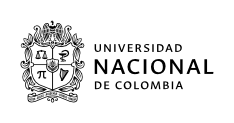
    </td>
    <td style="border:none; text-align:left; vertical-align:middle; font-size:30px; line-height:1.4; padding:0;">
      Maestría en ciencias agrarias<br>
      Facultad de Ciencias Agrarias<br>
      Sede Bogotá<br>
      Análisis epidemiológico de enfermedades en plantas
    </td>
  </tr>
</table>
<hr style="border:none; border-top:1.5px solid #000; margin:15px 0 15px 0;">
<div style="text-align:center; font-family:Calibri, Arial, sans-serif; font-size:50px; font-weight:bold; line-height:1.5;">

  **Taller 1. Modelación de la pudrición radical por <i>Phytophthora cinnamomi</i> en aguacate<br>**

  **Camila Janiris Calderón Martínez**
</div>
<hr style="border:none; border-top:1.5px solid #000; text-align:center; font-weight:bold; margin:20px 0 15px 0;">

texto en cursiva# **Taller 1 — Análisis Epidemiológico de Enfermedades en Plantas**
## Modelación de la Pudrición Radical por *Phytophthora cinnamomi* en Aguacate
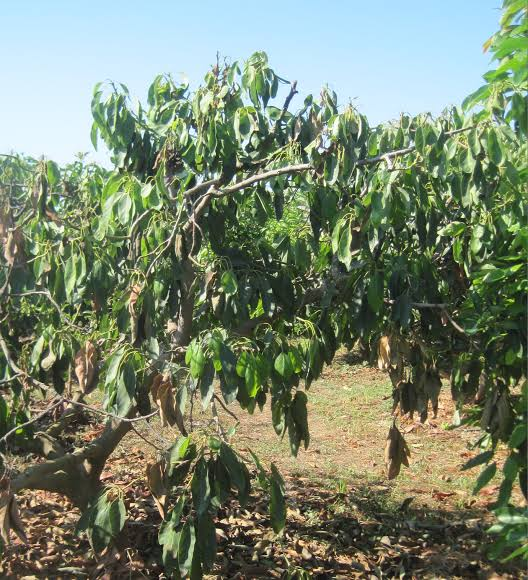

### Asignatura: **Análisis Epidemiológico**
**Preparado por:** *Joaquín Guillermo Ramírez Gil*

---

Este taller guía **paso a paso** la implementación de modelos epidemiológicos en Google Colab,
combinando **teoría, preguntas de estudio y práctica** sobre datos reales de campo.

### Caso de estudio
**Patosistema:** Pudrición radical del aguacate (*Phytophthora Root Rot*, PRR)
- **Patógeno:** *Phytophthora cinnamomi* (oomiceto habitante del suelo)
- **Hospedante:** copa **Hass** injertada sobre patrón (portainjerto) de **material antillano susceptible**
- **Escala de severidad:** `0` = sano · `1–4` = estados de enfermedad crecientes · `5` = severidad máxima
- **Interpretación epidemiológica (para este taller):**
  - Estado **5** = plantas que se asumen **removidas / muertas** (compartimento *Removidos, R*).
  - Plantas que **descienden** de un estado alto a uno inferior se consideran **nuevamente susceptibles**.
- **Diseño:** 3 lotes, evaluaciones cada **60 días** desde `D0` hasta `D1200` (21 tiempos).

### ⚠️ Uso de datos
> Los datos son **exclusivamente para fines académicos** de este ejercicio. Forman parte del manuscrito
> sometido a la revista *Phytopathology*: **"Multimodel approach enhances understanding of Phytophthora
> root rot spatial and temporal dynamics in avocado under scenarios of climate variability"**.
> Repositorio libre: https://github.com/agrocompuepidemlab/Multimodel-approach-of-Phytophthora-Root-Rot-spatial-and-temporal-dynamics-in-avocado-

---
### Contenido del taller
1. **Carga de datos y Análisis Exploratorio** — incidencia, severidad (por periodo y acumulada) y tasas de cambio
2. **Modelo Compartimental (SIR con removidos)**
3. **Modelo Compartimental con componente espacial**
4. **Modelo Basado en Agentes (Agent-Based Model, ABM)**
5. **Modelo Compartimental con análisis de redes**

Cada modelo incluye: **estructura matemática · asunciones · paso a paso · preguntas teóricas ·
para qué/cuándo se usa · requisitos de datos · métricas de ajuste, error y complejidad · práctica.**


## 0. Preparación del entorno

In [2]:
# Instalar dependencias (Colab)
!pip install openpyxl networkx -q

# Instalar dependencias (Colab)

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
import networkx as nx

np.random.seed(42)
plt.rcParams.update({'figure.figsize':(9,5),'axes.grid':True,'grid.alpha':0.25,'font.size':11})
C_OBS="#B7410E"; C_FIT="#2A9D8F"; C_ALT="#E9A23B"; C_R="#7B6FB0"
print("Entorno listo ✓")


Entorno listo ✓


In [3]:
# ===== SE SUBIERON LOS DATOS DESDE GOOGLE DRIVE =====
from google.colab import drive
drive.mount('/content/drive')
ARCHIVO = "/content/drive/MyDrive/MAESTRIA UNAL /ANALISIS EPIDEMIOLOGICO/TALLER 1/PRR_Unified_data_ThreeLots.xlsx"


Mounted at /content/drive


In [4]:
try:
    ARCHIVO
except NameError:
    ARCHIVO = "PRR_Unified_data_ThreeLots.xlsx"

xl = pd.ExcelFile(ARCHIVO)
print("Hojas disponibles:", xl.sheet_names)


Hojas disponibles: ['Dictionary_Data', 'Donmatias-L1', 'El Retiro-L2', 'La Ceja-L3']


### Práctica 1.1 — Explorar la estructura

**Lo que debes hacer:** carga las tres hojas de lotes, identifica las columnas de severidad (`D0`...`D1200`)
y revisa si hay valores fuera de la escala 0–5 (limpieza de datos).

In [5]:
LOTES = ['Donmatias-L1', 'El Retiro-L2', 'La Ceja-L3']

def cargar_lote(nombre):
    d = pd.read_excel(xl, nombre)
    Dcols = [c for c in d.columns if c.startswith('D') and c[1:].isdigit()]
    # LIMPIEZA: la escala válida es 0-5; cualquier otro valor -> NaN
    d[Dcols] = d[Dcols].where(d[Dcols].isin([0,1,2,3,4,5]))
    return d, Dcols

d1, Dcols = cargar_lote('Donmatias-L1')
times = np.array([int(c[1:]) for c in Dcols])   # días: 0,60,...,1200
print(f"Lote Donmatias-L1: {len(d1)} árboles · {len(Dcols)} tiempos ({times[0]}–{times[-1]} días)")
print("Coordenadas:", ['Easting','Northing'])
d1[['Point_ID','Easting','Northing']+Dcols[:5]].head()


Lote Donmatias-L1: 903 árboles · 21 tiempos (0–1200 días)
Coordenadas: ['Easting', 'Northing']


,Point_ID,Easting,Northing,D0,D60,D120,D180,D240
0,1,460792.37,718513.06,0,0,1,3,4
1,2,460789.38,718518.26,0,1,1,3,4
2,3,460787.08,718523.10,0,0,0,1,2
3,4,460778.86,718530.30,0,0,0,0,0
4,5,460783.42,718536.70,0,0,0,0,0


In [6]:
#SOLUCIÓN Práctica 1.1 — Estructura y limpieza de los 3 lotes
filas = []
for lote in LOTES:
    raw = pd.read_excel(xl, lote)
    Dc = [c for c in raw.columns if c.startswith('D') and c[1:].isdigit()]
    vals = raw[Dc].values
    fuera = ~np.isin(vals, [0,1,2,3,4,5]) & ~pd.isna(vals)
    arr = raw[Dc].where(raw[Dc].isin([0,1,2,3,4,5])).values.astype(float)
    dif = np.diff(arr, axis=1)
    filas.append({"Lote": lote, "Árboles": len(raw), "Tiempos": len(Dc),
                  "Celdas": vals.size, "Fuera_de_escala": int(fuera.sum()),
                  "Faltantes_originales": int(pd.isna(vals).sum()),
                  "Descensos_de_grado": int(np.nansum(dif < 0)),
                  "Árboles_que_descienden": int((dif < 0).any(axis=1).sum()),
                  "Salidas_del_grado_5": int(np.nansum((arr[:, :-1] == 5) & (arr[:, 1:] < 5)))})
    if fuera.any():
        r, c = np.where(fuera)
        for ri, ci in zip(r, c):
            print(f"⚠ {lote}: Point_ID={raw.loc[ri,'Point_ID']} · {Dc[ci]} = {vals[ri,ci]}  "
                  f"(serie: {raw.loc[ri, Dc].tolist()})")
limpieza = pd.DataFrame(filas)
print("\nColumnas de severidad:", Dcols[0], "...", Dcols[-1], f"({len(Dcols)} tiempos cada 60 días)")
print("Otras columnas útiles:", [c for c in d1.columns if c not in Dcols])
limpieza

⚠ Donmatias-L1: Point_ID=970 · D600 = 23  (serie: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(2), np.int64(23), np.int64(2), np.int64(4), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5), np.int64(5)])

Columnas de severidad: D0 ... D1200 (21 tiempos cada 60 días)
Otras columnas útiles: ['Lot_ID', 'Lot_Label', 'GPS_Height', 'Vert_Prec', 'Horz_Prec', 'Northing', 'Easting', 'Point_ID', 'ORIG_FID']


,Lote,Árboles,Tiempos,Celdas,Fuera_de_escala,Faltantes_originales,Descensos_de_grado,Árboles_que_descienden,Salidas_del_grado_5
0,Donmatias-L1,903,21,18963,1,0,6,5,1
1,El Retiro-L2,1338,21,28098,0,0,0,0,0
2,La Ceja-L3,1666,21,34986,0,0,0,0,0


### <font color="green">**Resultado Práctica 1.1**</font>
- En el analisis exploratorio de los datos se puede evidenciar que cada lote tiene 21 columnas de severidad (`D0` a `D1200`, distanciadas cada 60 días), coordenadas (`Easting`, `Northing`) y una cota por árbol (`GPS_Height`)
- Fuera de escala de severidad (0-5) hay un solo valor, `23` en Donmatías-L1 (Point_ID 970, D600). Su serie es `… 0, 2, 23, 2, 4, 5 …`, así que es posible que sea un error de digitación. Se convierte en `NaN` y se excluye del conteo de ese tiempo.
- No hay datos faltantes originales en ningún lote.
- **Descensos de grado de severidad:** Se encontraron 6 descensos en 5 árboles, todos en Donmatías-L1.
  - *P. cinnamomi* pudre las raíces y el árbol casi nunca se cura de forma espontánea. Por tal motivo un árbol que "sana" (baja el grado de severidad) y unos meses después vuelve a aparecer enfermo o muerto probablemente nunca estuvo sano, por lo que lo consideramos nuevamente susceptible: seguía infectado. Lo que cambió fue cómo se veía la copa o cómo lo calificó el evaluador. Cuatro de los cinco árboles vuelven a subir después de bajar, lo que apoya esa idea.
  - Uno de ellos (Arbol 1099) sale del grado 5 (5→4→4→5), lo que contradice que R sea absorbente pues el modelo SIR supone que el grado 5 es removido y una vez muerto, el árbol no sale de ahí. Este árbol pasa de 5 a 4 y luego regresa a 5. Un árbol muerto no revive, así que lo más probable es que se calificó 5 demasiado pronto o que tuvo un rebrote temporal antes de colapsar del todo.
   

|Árbol	|Tramo de la serie	      
|-------|-------------------------
|36	    |…0, 1, **0**, 3, 3,** 0**, 5, 5…
|45|	…0, 2, 2, **0**, 3, 3…|
|60|	…1, 1, 1, **0**, 3, 3, 5…|
|383|	…0, 1, **0**|
|1099|	…5, 5, 5, **4, 4**, 5, 5…

### Conceptos: Incidencia, Severidad y Tasas

**Incidencia (I):** proporción de plantas enfermas (severidad ≥ 1).
$$I(t) = \frac{\text{n.º de plantas con severidad} \ge 1}{N} \times 100$$

**Índice de severidad (Townsend–Heuberger):** resume la escala ordinal (0–5) en un % continuo.
$$S(t) = \frac{\sum (n_i \cdot v_i)}{N \cdot V} \times 100$$
donde $n_i$ = plantas en el grado $v_i$, $N$ = total de plantas, $V$ = grado máximo (5).

**Tasa de cambio (velocidad de la epidemia)** entre evaluaciones:
$$r(t) = \frac{X(t_{k+1}) - X(t_k)}{t_{k+1}-t_k}$$


In [7]:
def metricas_lote(d, Dcols, times):
    N = len(d)
    inc = np.array([(d[c] >= 1).sum()/N*100 for c in Dcols])          # incidencia (%)
    sev = np.array([d[c].sum()/(N*5)*100 for c in Dcols])             # severidad THI (%)
    r_inc = np.diff(inc)/np.diff(times)                               # tasa incidencia
    r_sev = np.diff(sev)/np.diff(times)                               # tasa severidad
    return inc, sev, r_inc, r_sev

# Donmatias-L1 (se conservan estas variables porque otras celdas las usan)
inc1, sev1, rinc1, rsev1 = metricas_lote(d1, Dcols, times)

# Tabla de los tres lotes
tabla = pd.DataFrame({"Día": times})
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    inc, sev, _, _ = metricas_lote(d, Dc, times)
    tabla[(lote, "Incidencia_%")] = inc.round(1)
    tabla[(lote, "Severidad_%")] = sev.round(1)
tabla = tabla.set_index("Día")
tabla.columns = pd.MultiIndex.from_tuples(tabla.columns)
print("Incidencia y severidad por periodo — tres lotes:")
tabla


Incidencia y severidad por periodo — tres lotes:


Donmatias-L1             El Retiro-L2               La Ceja-L3  \
     Incidencia_% Severidad_% Incidencia_% Severidad_% Incidencia_%   
Día                                                                   
0             0.0         0.0          0.0         0.0          0.0   
60           14.4         5.5          8.2         1.6          8.7   
120          16.9         9.4         17.5         3.5         17.7   
180          19.4        12.9         20.0         4.0         20.1   
240          21.3        15.1         21.4         4.3         22.5   
300          24.3        18.2         24.3         6.4         25.1   
360          26.9        20.1         26.8        10.2         27.7   
420          28.0        21.6         28.3        15.6         28.6   
480          29.6        23.1         29.7        20.1         30.2   
540          30.8        24.7         31.3        23.2         31.6   
600          33.1        26.6         33.6        25.4         34.4   
660          34.1        27.9         34.6        27.2         35.9   
720          35.1        29.2         35.4        29.0         36.6   
780          35.1        30.1         36.0        30.5         37.4   
840          41.0        34.0         40.9        32.8         42.0   
900          42.3        35.6         41.9        34.1         43.6   
960          43.3        37.0         43.7        35.4         45.4   
1020         49.5        40.7         48.2        37.2         50.5   
1080         51.2        42.7         50.8        38.6         52.2   
1140         52.0        43.8         51.5        39.6         53.5   
1200         52.5        44.4         52.0        40.6         54.0   

                  
     Severidad_%  
Día               
0            0.0  
60           1.7  
120          3.5  
180          4.0  
240          4.6  
300          6.4  
360         10.5  
420         15.6  
480         20.2  
540         23.4  
600         26.1  
660         28.2  
720         29.8  
780         31.3  
840         33.6  
900         35.2  
960         36.7  
1020        38.6  
1080        39.7  
1140        40.8  
1200        41.7

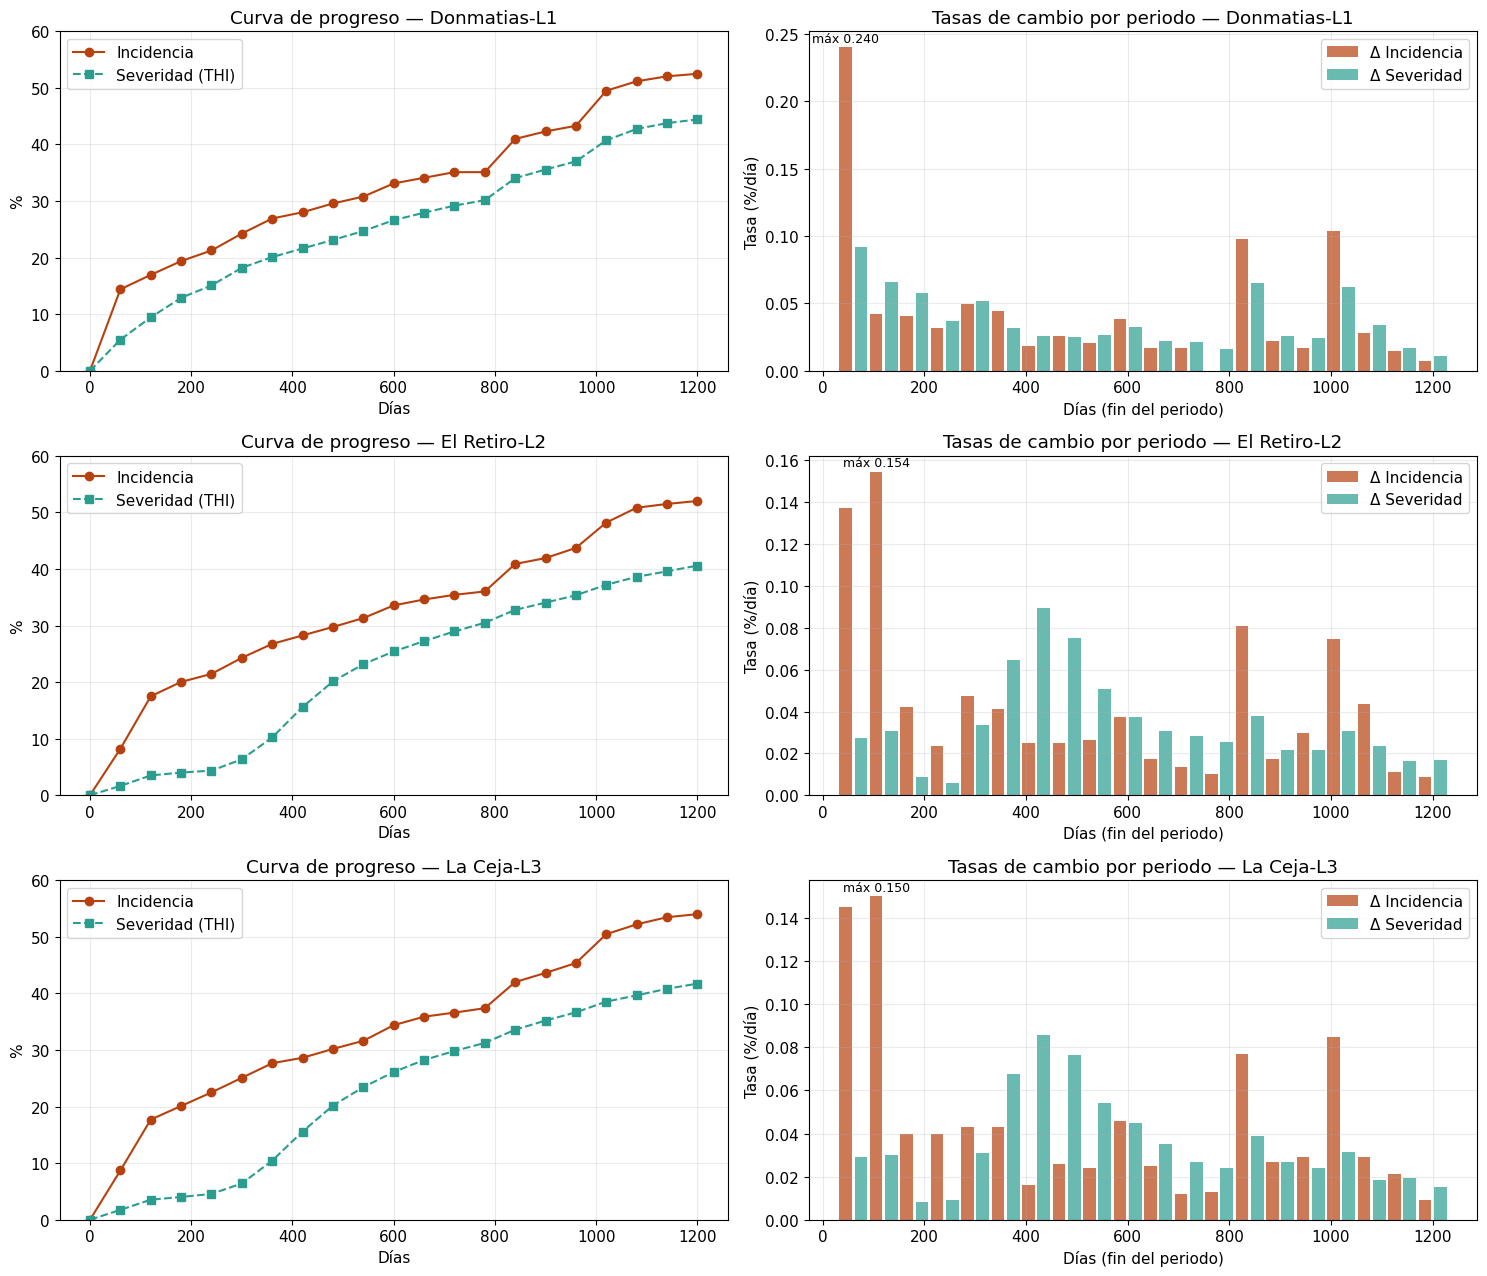

In [8]:
# Curvas de progreso de la enfermedad (CPE) — incidencia y severidad, POR LOTE
fig, ax = plt.subplots(len(LOTES), 2, figsize=(15, 4.3 * len(LOTES)))
for f, lote in enumerate(LOTES):
    d, Dc = cargar_lote(lote)
    inc, sev, rinc, rsev = metricas_lote(d, Dc, times)

    # Curva de progreso
    ax[f, 0].plot(times, inc, "o-", color=C_OBS, label="Incidencia")
    ax[f, 0].plot(times, sev, "s--", color=C_FIT, label="Severidad (THI)")
    ax[f, 0].set_ylim(0, 60)
    ax[f, 0].set_xlabel("Días"); ax[f, 0].set_ylabel("%")
    ax[f, 0].set_title(f"Curva de progreso — {lote}"); ax[f, 0].legend()

    # Tasas de cambio por periodo
    ax[f, 1].bar(times[1:]-15, rinc, width=25, color=C_OBS, alpha=0.7, label="Δ Incidencia")
    ax[f, 1].bar(times[1:]+15, rsev, width=25, color=C_FIT, alpha=0.7, label="Δ Severidad")
    k = np.argmax(rinc)
    ax[f, 1].annotate(f"máx {rinc[k]:.3f}", (times[k+1]-15, rinc[k]), xytext=(0, 4),
                      textcoords="offset points", ha="center", fontsize=9)
    ax[f, 1].set_xlabel("Días (fin del periodo)"); ax[f, 1].set_ylabel("Tasa (%/día)")
    ax[f, 1].set_title(f"Tasas de cambio por periodo — {lote}"); ax[f, 1].legend()

plt.tight_layout(); plt.show()

### <font color="green">**Analisis de las graficas**</font>
  - Los tres lotes tienen la misma forma de curva, tienen un arranque rapido en los primero 60-120 dias
    - Donmatías pasa de 0 a ≈ 14% de incidencia en un solo periodo
    - El Retiro y La Ceja reparten ese salto en dos periodos (D60 y D120) y llegan a ≈ 18% de incidencia.
  - Luego hay un crecimiento lento entre D120 y D780, con tasas de apenas 0.01–0.05 %/día.
  - Y hay dos pulsos tardios que se dan al tiempo en los tres lotes D780–D840 y D960–D1020, seguidos de una desaceleración: al final las tasas son menores de 0.02 %/día y la incidencia se estabiliza en 52–54%.

Los tres lotes estan geograficamente separados, sin contacto entre sus árboles. Si los pulsos fueran solo contagio dentro de cada lote, no tendrían por qué coincidir en la misma fecha. Que coincidan apunta a un factor ambiental común. *P. cinnamomi* necesita suelo saturado para liberar zoosporas (Del Castillo-González et al., 2024), así que un periodo muy lluvioso dispara infecciones en todas las fincas a la vez. Además, los dos pulsos están separados por ≈ 180 días, lo que encaja con el régimen de lluvias bimodal de Antioquia (Reyes-Cáceres & García-Ossa, 2026).

**Nota**: Esta es una hipotesis mia, ya que en el taller no se dan fechas reales para contrarestar este comportamiento con las variables ambientales


- El comportamiento de la severidad es parecido en el lote El retiro y La Ceja, sin emebargo en Donmatias se comporta diferente
  - En Donmatias desde el inicio los árboles enfermos se deterioran rápido
  - El Retiro y La Ceja: la severidad es menor de 11% durante casi un año. En D240 la incidencia es ≈ 22% pero la severidad apenas 4–5%. Luego, entre D300 y D540, la severidad se dispara, con su tasa máxima (≈ 0.09 %/día) en D360–D420.

### Práctica 1.2 — Incidencia y severidad **acumulada** (AUDPC)

El **AUDPC** (Área Bajo la Curva de Progreso de la Enfermedad) resume toda la epidemia en un valor:
$$\text{AUDPC} = \sum_{k=1}^{n-1} \frac{y_k + y_{k+1}}{2}\,(t_{k+1}-t_k)$$

**Lo que debes hacer:** calcula el AUDPC de incidencia y severidad para los tres lotes y compáralos.

Comparación entre lotes:


,Lote,N,Incid_final_%,Sever_final_%,AUDPC_incid,AUDPC_sever
0,Donmatias-L1,903,52.5,44.4,39269.0,31236.0
1,El Retiro-L2,1338,52.0,40.6,39013.0,26336.0
2,La Ceja-L3,1666,54.0,41.7,40246.0,27047.0


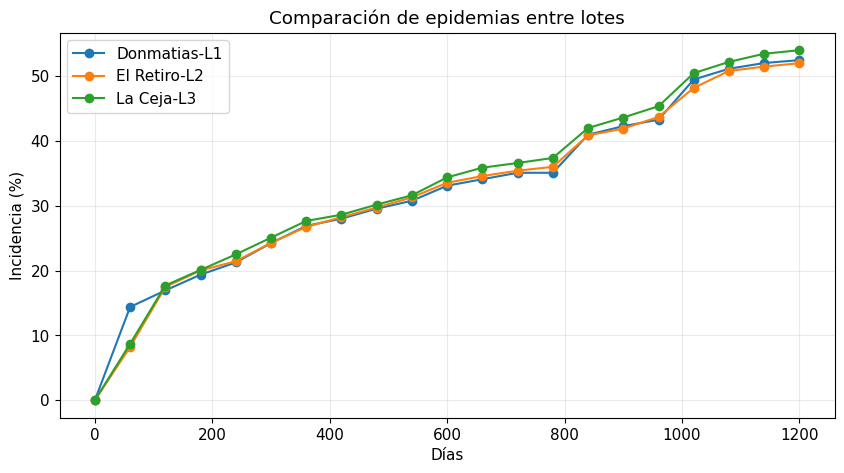

In [9]:
def audpc(y, t):
    return float(np.trapz(y, t)) if hasattr(np,"trapz") else float(np.trapezoid(y, t))   # regla del trapecio

# Comparar los 3 lotes
resumen = []
curvas = {}
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    inc, sev, rinc, rsev = metricas_lote(d, Dc, times)
    curvas[lote] = (inc, sev)
    resumen.append({"Lote":lote, "N":len(d),
                    "Incid_final_%":round(inc[-1],1), "Sever_final_%":round(sev[-1],1),
                    "AUDPC_incid":round(audpc(inc,times),0), "AUDPC_sever":round(audpc(sev,times),0)})
resumen = pd.DataFrame(resumen)
print("Comparación entre lotes:")
display(resumen)

plt.figure(figsize=(10,5))
for lote in LOTES:
    plt.plot(times, curvas[lote][0], "o-", label=lote)
plt.xlabel("Días"); plt.ylabel("Incidencia (%)"); plt.title("Comparación de epidemias entre lotes"); plt.legend(); plt.show()


### Preguntas teóricas — Bloque 1 (Exploración)
1. ¿Qué diferencia conceptual hay entre **incidencia** y **severidad**? ¿Por qué pueden divergir?
2. ¿Por qué el índice de Townsend–Heuberger es preferible a un simple promedio de los grados?
3. Interpreta el **AUDPC**: ¿qué significa que un lote tenga mayor AUDPC que otro?
4. Observando las **tasas de cambio**, ¿en qué periodo la epidemia fue más rápida? ¿Qué factores del
   patosistema (*P. cinnamomi* / suelo / clima) podrían explicarlo?
5. ¿Qué implica, epidemiológicamente, encontrar valores fuera de la escala (p. ej. `23`) y cómo los trataste?


,Lote,Máx_tasa_incid_%/día,Periodo_incid,Máx_tasa_sever_%/día,Periodo_sever,Tasa_media_incid_%/día,2º_pico_incid
0,Donmatias-L1,0.240,D0–D60,0.092,D0–D60,0.044,D960–D1020 (0.103)
1,El Retiro-L2,0.154,D60–D120,0.090,D360–D420,0.043,D60–D120 (0.154)
2,La Ceja-L3,0.150,D60–D120,0.086,D360–D420,0.045,D60–D120 (0.150)


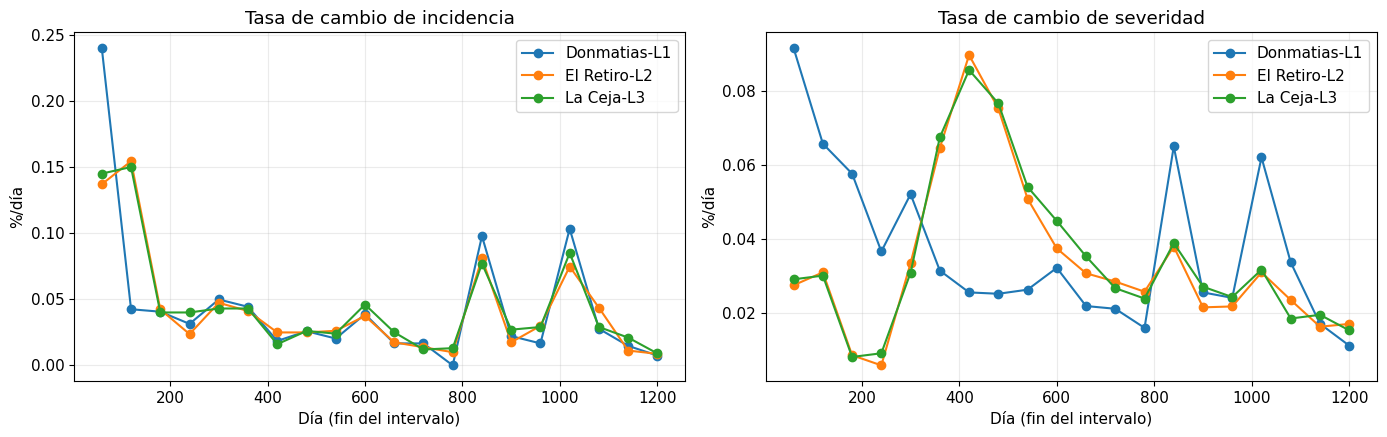

In [10]:
# Tasas de cambio de incidencia y severidad
tasas = []
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    inc, sev, rinc, rsev = metricas_lote(d, Dc, times)
    k = np.argmax(rinc); ks = np.argmax(rsev)
    tasas.append({"Lote": lote,
                  "Máx_tasa_incid_%/día": round(rinc[k], 3), "Periodo_incid": f"D{times[k]}–D{times[k+1]}",
                  "Máx_tasa_sever_%/día": round(rsev[ks], 3), "Periodo_sever": f"D{times[ks]}–D{times[ks+1]}",
                  "Tasa_media_incid_%/día": round(rinc.mean(), 3)})
    # 2.º pico, excluyendo el primer intervalo (aparición inicial)
    k2 = np.argmax(rinc[1:]) + 1
    tasas[-1]["2º_pico_incid"] = f"D{times[k2]}–D{times[k2+1]} ({rinc[k2]:.3f})"
display(pd.DataFrame(tasas))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    inc, sev, rinc, rsev = metricas_lote(d, Dc, times)
    ax[0].plot(times[1:], rinc, "o-", label=lote); ax[1].plot(times[1:], rsev, "o-", label=lote)
ax[0].set_title("Tasa de cambio de incidencia"); ax[1].set_title("Tasa de cambio de severidad")
for a in ax: a.set_xlabel("Día (fin del intervalo)"); a.set_ylabel("%/día"); a.legend()
plt.tight_layout(); plt.show()

### <font color="green">**Respuestas — Bloque 1 (Exploración)**</font>

**1.¿Qué diferencia conceptual hay entre incidencia y severidad?**

La incidencia mide cuántas plantas están enfermas en una población (presencia/ausencia, severidad ≥ 1), pero no indica el nivel de daño de la enfermedad. A diferencia de la severidad que si mide cuánto daño tienen (intensidad en la escala 0–5 en este caso).

**¿Por qué pueden divergir?**

Pueden divergir porque tener muchos casos no necesariamente significa que la enfermedad sea grave, y viceversa. Una planta cuenta igual para la incidencia con grado 1 o con grado 5.  Por ejemplo en este caso al inicio, la incidencia sube rápido mientras la severidad va detrás, porque los árboles recién infectados están en grados bajos. Al final, la incidencia se estabiliza pero la severidad sigue subiendo porque los árboles ya enfermos progresan hacia un grado de severidad mayor. En Donmatías la brecha se cierra con el tiempo, al final la severidad (44.4%) se acerca a la incidencia (52.5%) porque muchos enfermos llegaron a grado 5.

**2. ¿Por qué el índice de Townsend–Heuberger es preferible a un simple promedio de los grados?**

El índice es preferible al simple promedio de los grados porque incorpora la frecuencia de individuos en cada categoría y permite expresar la severidad como un porcentaje relativo de enfermedad. Ademas compara el total de plantas y lo normaliza con el grado de severidad maxima posible, lo que permite comparar, pues se expresa en un % entre 0 y 100, comparable entre lotes de distinto tamaño y entre escalas con distinto número de grados.

**3. Interpreta el AUDPC: ¿qué significa que un lote tenga mayor AUDPC que otro?**

Primero que todo hay que entender que el AUDPC es la cantidad totoal de enfermedad acumulada durante los 1200 dias (en nuestro caso) , expresada en %.dias.  Que un lote tenga mayor AUDPC indica que acumuló más enfermedad durante el periodo de evaluación. Puede ser que tuvo una mayor severidad de la enfermedad, más presión de inóculo, más pérdida acumulada, una aparicion mas temprana de la enfermedad, mayor duraciñon de la enfermedad o una combinacion de las anteriores (Madden et al., 2007).

En los datos:
- La Ceja tiene el mayor AUDPC de incidencia (40246), es decir, más árboles enfermos a lo largo del tiempo. Sin embargo la difencia entre los lotes no es mucha, la epidemia se extendió de forma parecida en los tres. Sin embargo, el AUDPC está en porcentaje, pero en número de árboles La Ceja tiene ≈ 900 enfermos al final, contra ≈ 696 en El Retiro y ≈ 474 en Donmatías. En pérdidas absolutas y en costo de manejo, la Ceja es el lote con el problema más grande.
- Donmatías tiene el mayor AUDPC de severidad (31236): sus árboles enfermos se deterioraron mas y durante mas tiempo.

  - Donmatías probablemente perdió más cosecha acumulada, aunque al final tenga el mismo porcentaje de enfermos. Y esto es importante ya que la pérdida de producción de un aguacate depende de cuánto daño tiene , no solo de si está enfermo. Un árbol en grado 4 durante dos años produce mucho menos que uno en grado 1.
  - Ademas al tener una severidad alta sostenida en el tiempo implica que hay mas inóculo en el suelo , lo que pesaa en futuras resiembras. Y esas resiembras seran mas pronto, pues habrá mas mortalidad temprana.
  - Por lo que en Donmatías la urgencia es frenar el deterioro de los árboles ya infectados.

**4. Observando las tasas de cambio, ¿en qué periodo la epidemia fue más rápida? ¿Qué factores del patosistema (*P. cinnamomi* / suelo / clima) podrían explicarlo?** (Tabla y gráfico de tasas arriba.)

En los tres lotes el periodo mas rapido ocurre en la fase inicial de la epidemia entre los 0 y 120 dias.
- Donmatías: la tasa máxima de incidencia está entre D0–D60 (0.24 %/día), cuando aparece el 14% de plantas enfermas de golpe. Esto sugiere inóculo ya presente en el suelo al establecer el lote, o síntomas que aún no eran visibles en D0. Hay un segundo pulso en D780–D840 y D960–D1020 (≈ 0.10 %/día), tras una fase lenta.
- El Retiro y La Ceja: la incidencia crece más rápido en D60–D120 (≈ 0.15 %/día), y la severidad tiene su pico en D360–D420.

**Factores del patosistema:**
- Teniendo en cuenta que el periodo donde la epidemia fue mas rápida fue el mismo, lo asociaria con un fenomeno climatico. Pudieron presentarse altas precipitaciones en este periodo de tiempo lo que favorecio al patogeno, pues *P. cinnamomi* depende del agua libre en el suelo. Los esporangios liberan zoosporas cuando el suelo está saturado, y la infección se dispara con suelos encharcados y mal drenados  (Del Castillo-González et al., 2024).

- A esto se le puede sumar suelos arcillosos o compactados indicando ausencia de drenaje lo que favorece la retención de agua, propicio para el patógeno.

- También se puede asociar a una presión alta del inoculo en el suelo sumado con el portainjerto antillano susceptible.


**5. ¿Qué implica, epidemiológicamente, encontrar valores fuera de la escala (p. ej. 23) y cómo los trataste?**

Epidemiológicamente, un `23` no existe (la escala es 0–5): es un error de medición o digitación y no un estado biológico. Si se deja, infla la severidad  de ese tiempo y puede romper modelos que asumen 0–5. Lo traté como dato faltante (NaN). Por su contexto (2 → 23 → 2) también sería razonable imputarlo como 2 , pero se recomienda revisar la planilla de campo si se tuviera. Lo importante es documentar la decisión y verificar que no cambie las conclusiones: aquí afecta 1 de 18963 datos.

---
## 2. Modelo Compartimental (SIR con removidos)

### Estructura matemática
Modelo **S–I–R** adaptado a la PRR. Cada árbol es un "sitio" que transita entre compartimentos:

$$
\frac{dS}{dt} = -\beta \frac{S\,I}{N} \qquad
\frac{dI}{dt} = \beta \frac{S\,I}{N} - \gamma\, I \qquad
\frac{dR}{dt} = \gamma\, I
$$

- **S** = plantas **sanas/susceptibles** (severidad 0)
- **I** = plantas **infectadas** (severidad 1–4)
- **R** = plantas **removidas / muertas** (severidad 5)
- $\beta$ = tasa de transmisión · $\gamma$ = tasa de remoción (paso a muerte) · $N = S+I+R$
- **Número reproductivo básico:** $R_0 = \beta/\gamma$ (epidemia si $R_0 > 1$)

> **Nota del caso:** el estado 5 se asume **removido (R)**. Las plantas que **bajan** de un estado alto
> a uno menor vuelven a considerarse susceptibles/infectadas según su nuevo grado (dinámica reversible
> parcial que discutiremos).

### Asunciones
1. Población **cerrada y homogénea** (mezcla uniforme; sin estructura espacial explícita).
2. Tasas **constantes** en el tiempo.
3. Transiciones tipo **exponencial** (sin memoria).
4. **R es absorbente**: una planta muerta (grado 5) no se recupera.
5. Dinámica **determinística** a escala de lote.

### ¿Qué preguntas epidemiológicas resuelve?
- ¿Cuál es la **velocidad de transmisión** ($\beta$) de la PRR en el lote?
- ¿La epidemia es **auto-sostenida** ($R_0>1$)?
- ¿Qué proporción final de plantas se perderá (**tamaño final de la epidemia**)?

### ¿Para qué y cuándo se usa?
Para **entender el proceso** y estimar parámetros interpretables; ideal cuando se tiene una **serie temporal**
de incidencia/severidad y se busca comparar la agresividad entre lotes o escenarios.

### Requisitos de datos
Serie temporal de la proporción de plantas por estado (mínimo incidencia acumulada) en ≥ 5–6 tiempos.


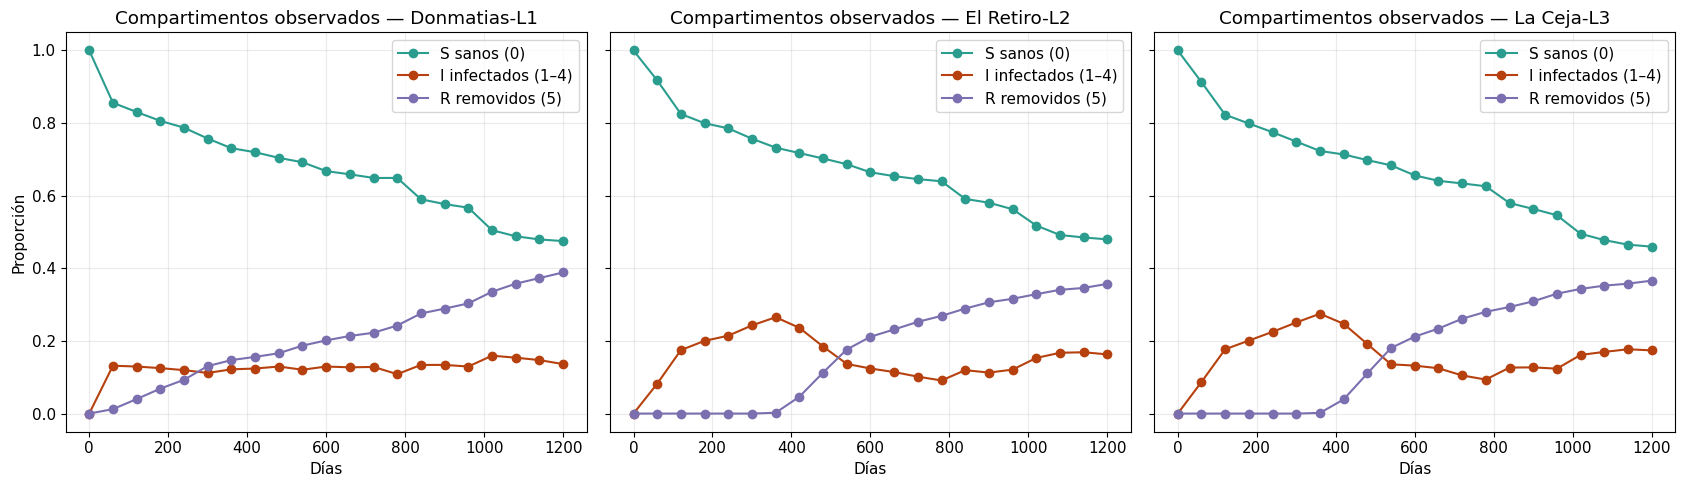

,S final,I final,R final,I+R final,Máx. I,Día del máx. I
Donmatias-L1,0.475,0.136,0.389,0.525,0.159,1020.0
El Retiro-L2,0.480,0.163,0.357,0.520,0.265,360.0
La Ceja-L3,0.460,0.174,0.366,0.540,0.275,360.0


In [11]:
# Preparar la serie S-I-R observada (proporciones) para los tres lotes
def series_SIR(d, Dcols):
    N=len(d)
    S=np.array([(d[c]==0).sum() for c in Dcols])/N
    I=np.array([((d[c]>=1)&(d[c]<=4)).sum() for c in Dcols])/N
    R=np.array([(d[c]==5).sum() for c in Dcols])/N
    return S,I,R

# Calcular S, I, R e incidencia acumulada para cada lote
series = {}
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    S, I, R = series_SIR(d, Dc)
    series[lote] = {"S": S, "I": I, "R": R, "inc_acum": I + R}

# Donmatias-L1 (se conservan estas variables porque las celdas siguientes las usan)
d1, Dcols = cargar_lote('Donmatias-L1')
S_obs, I_obs, R_obs = series['Donmatias-L1']["S"], series['Donmatias-L1']["I"], series['Donmatias-L1']["R"]
inc_acum = I_obs + R_obs   # incidencia acumulada = infectados + removidos

# Gráfica: un panel por lote
fig, ax = plt.subplots(1, len(LOTES), figsize=(17, 5), sharey=True)
for a, lote in zip(ax, LOTES):
    s = series[lote]
    a.plot(times, s["S"], "o-", color="#2A9D8F", label="S sanos (0)")
    a.plot(times, s["I"], "o-", color=C_OBS, label="I infectados (1–4)")
    a.plot(times, s["R"], "o-", color=C_R, label="R removidos (5)")
    a.set_xlabel("Días"); a.set_title(f"Compartimentos observados — {lote}"); a.legend()
ax[0].set_ylabel("Proporción")
plt.tight_layout(); plt.show()

# Tabla resumen al final del periodo (D1200)
pd.DataFrame({lote: {"S final": round(s["S"][-1], 3), "I final": round(s["I"][-1], 3),
                     "R final": round(s["R"][-1], 3), "I+R final": round(s["inc_acum"][-1], 3),
                     "Máx. I": round(s["I"].max(), 3), "Día del máx. I": int(times[np.argmax(s["I"])])}
              for lote, s in series.items()}).T


### Ajuste por **mínimos cuadrados sobre la ODE**
Estimamos $\beta$ y $\gamma$ integrando el sistema y minimizando el error cuadrático con los datos.

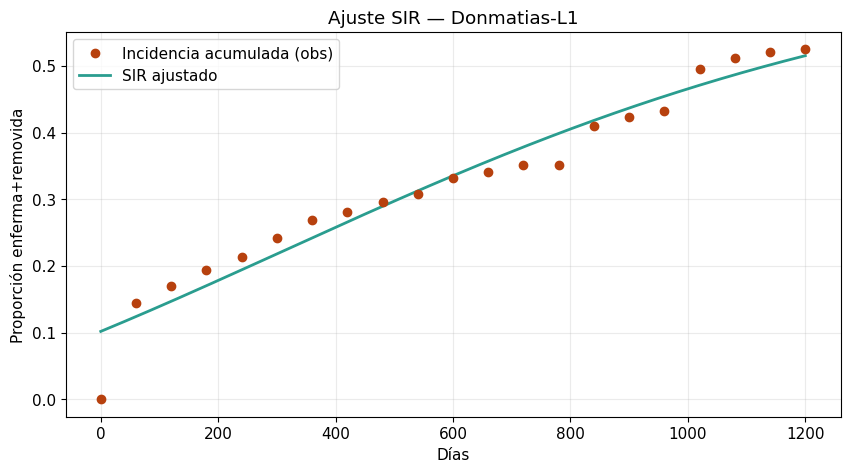

β = 0.0040 /día   γ = 0.0026 /día   R0 = β/γ = 1.54
Tiempo medio en estado infeccioso ≈ 386 días


In [12]:
def sir(y,t,beta,gamma):
    S,I,R=y; Nn=S+I+R
    return [-beta*S*I/Nn, beta*S*I/Nn-gamma*I, gamma*I]

def sir_incidencia(t,beta,gamma,I0):
    sol=odeint(sir,[1-I0,I0,0],t,args=(beta,gamma))
    return sol[:,1]+sol[:,2]   # I+R (incidencia acumulada)

p,cov=curve_fit(sir_incidencia,times,inc_acum,p0=[0.005,0.002,0.01],
                bounds=([0,0,0],[1,1,0.2]),maxfev=30000)
beta,gamma,I0=p
tt=np.linspace(0,1200,300)
pred=sir_incidencia(times,*p)

plt.figure(figsize=(10,5))
plt.scatter(times,inc_acum,color=C_OBS,zorder=3,label="Incidencia acumulada (obs)")
plt.plot(tt,sir_incidencia(tt,*p),color=C_FIT,lw=2,label="SIR ajustado")
plt.xlabel("Días"); plt.ylabel("Proporción enferma+removida"); plt.title("Ajuste SIR — Donmatias-L1"); plt.legend(); plt.show()

print(f"β = {beta:.4f} /día   γ = {gamma:.4f} /día   R0 = β/γ = {beta/gamma:.2f}")
print(f"Tiempo medio en estado infeccioso ≈ {1/gamma:.0f} días")


### Métricas de ajuste, error y complejidad
Reportamos las tres dimensiones (como en la teoría de evaluación de modelos).

In [13]:
def metricas_modelo(y_obs, y_pred, k, n=None):
    n = n if n else len(y_obs)
    resid = y_obs - y_pred
    rss = np.sum(resid**2)
    rmse = np.sqrt(np.mean(resid**2))
    mae = np.mean(np.abs(resid))
    ss_tot = np.sum((y_obs-np.mean(y_obs))**2)
    r2 = 1 - rss/ss_tot
    aic = n*np.log(rss/n) + 2*k
    aicc = aic + (2*k*(k+1))/(n-k-1) if n-k-1>0 else np.nan
    bic = n*np.log(rss/n) + k*np.log(n)
    return {"R2":round(r2,3),"RMSE":round(rmse,4),"MAE":round(mae,4),
            "AIC":round(aic,1),"AICc":round(aicc,1),"BIC":round(bic,1),"k_params":k}

m_sir = metricas_modelo(inc_acum, pred, k=3)
print("Métricas del modelo SIR:")
print("  Ajuste     → R² =", m_sir["R2"])
print("  Error      → RMSE =", m_sir["RMSE"], "| MAE =", m_sir["MAE"])
print("  Complejidad→ AIC =", m_sir["AIC"], "| BIC =", m_sir["BIC"], "| k =", m_sir["k_params"])
pd.DataFrame([m_sir])


Métricas del modelo SIR:
  Ajuste     → R² = 0.949
  Error      → RMSE = 0.0304 | MAE = 0.0228
  Complejidad→ AIC = -140.7 | BIC = -137.6 | k = 3


,R2,RMSE,MAE,AIC,AICc,BIC,k_params
0,0.949,0.0304,0.0228,-140.7,-139.3,-137.6,3


###  Práctica 2 — Ajusta el SIR a los 3 lotes
**Lo que debes hacer:** repite el ajuste para *El Retiro-L2* y *La Ceja-L3*, compara $R_0$ y las métricas.
¿Qué lote tiene la epidemia más agresiva?


,Lote,β (/día),±EE β,γ (/día),±EE γ,I0,R0=β/γ,1/γ (días),Reducción β para R0<1 (%),Tamaño final teórico (%),R2,RMSE,MAE,AIC,AICc,BIC,k_params
0,Donmatias-L1,0.0040,0.0012,0.0026,0.0011,0.102,1.54,386,35.1,60.9,0.949,0.0304,0.0228,-140.7,-139.3,-137.6,3
1,El Retiro-L2,0.0053,0.0015,0.0038,0.0014,0.086,1.40,263,28.3,50.7,0.953,0.0297,0.0241,-141.8,-140.4,-138.6,3
2,La Ceja-L3,0.0051,0.0014,0.0035,0.0013,0.090,1.46,288,31.4,55.5,0.955,0.0303,0.0245,-140.9,-139.5,-137.8,3


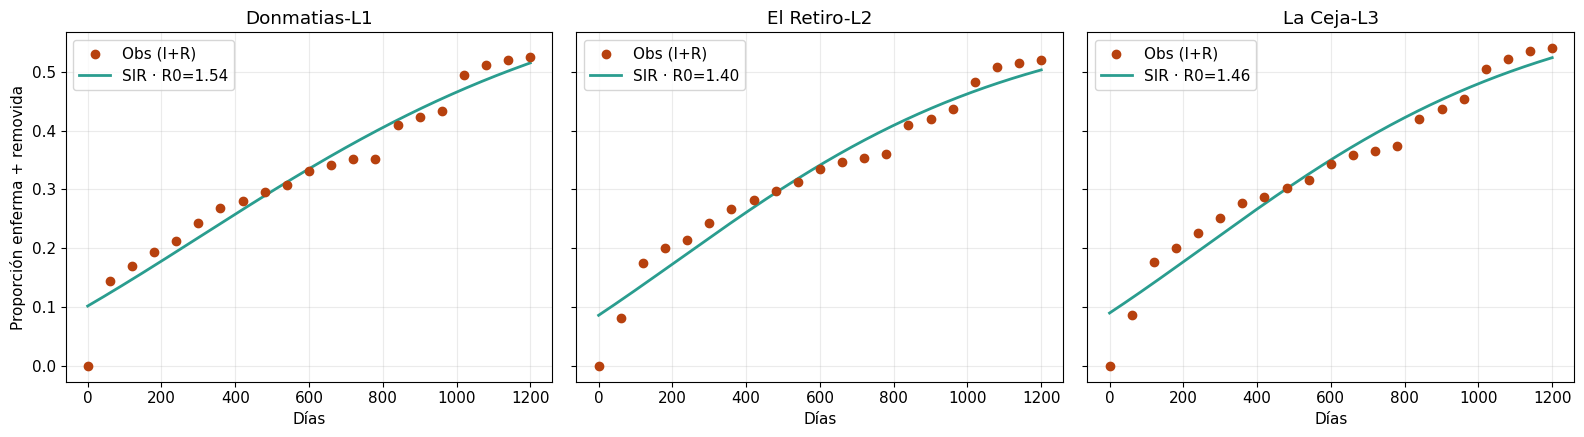

Lote con mayor R0: Donmatias-L1 (R0 = 1.54)


In [14]:
# SOLUCIÓN Práctica 2 — SIR ajustado a los 3 lotes
res_sir, fits = [], {}
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    S_o, I_o, R_o = series_SIR(d, Dc)
    y = I_o + R_o
    p, cov = curve_fit(sir_incidencia, times, y, p0=[0.005, 0.002, 0.01],
                       bounds=([0, 0, 0], [1, 1, 0.2]), maxfev=30000)
    b, g, i0 = p
    se = np.sqrt(np.diag(cov))
    m = metricas_modelo(y, sir_incidencia(times, *p), k=3)
    fits[lote] = (y, p)
    res_sir.append({"Lote": lote, "β (/día)": round(b, 4), "±EE β": round(se[0], 4),
                    "γ (/día)": round(g, 4), "±EE γ": round(se[1], 4), "I0": round(i0, 3),
                    "R0=β/γ": round(b / g, 2), "1/γ (días)": round(1 / g),
                    "Reducción β para R0<1 (%)": round(max(0, (1 - g / b) * 100), 1),
                    "Tamaño final teórico (%)": None, **m})
    # tamaño final del SIR clásico: z = 1 - exp(-R0 z)
    R0 = b / g
    z = 0.5
    for _ in range(500): z = 1 - np.exp(-R0 * z)
    res_sir[-1]["Tamaño final teórico (%)"] = round(z * 100, 1) if R0 > 1 else 0.0
tabla_sir = pd.DataFrame(res_sir)
display(tabla_sir)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
tt = np.linspace(0, 1200, 300)
for ax, lote in zip(axes, LOTES):
    y, p = fits[lote]
    ax.scatter(times, y, color=C_OBS, zorder=3, label="Obs (I+R)")
    ax.plot(tt, sir_incidencia(tt, *p), color=C_FIT, lw=2, label=f"SIR · R0={p[0]/p[1]:.2f}")
    ax.set_title(lote); ax.set_xlabel("Días"); ax.legend()
axes[0].set_ylabel("Proporción enferma + removida")
plt.tight_layout(); plt.show()
mas_agresivo = tabla_sir.sort_values("R0=β/γ", ascending=False).iloc[0]
print(f"Lote con mayor R0: {mas_agresivo['Lote']} (R0 = {mas_agresivo['R0=β/γ']})")

### <font color="green">**Resultado práctica 2**</font>

- El ajuste es igual de bueno en los tres lotes (R² ≈ 0.95, RMSE ≈ 0.03, AIC ≈ −141).
- Donmatías tiene la epidemia más agresiva, pues tiene el mayor R0 (1.54), el mayor tamaño final teórico (61%) y el mayor AUDPC de severidad.
- El Retiro tiene la transmisión más rápida (β mayor), pero sus árboles pasan antes a grado 5 (γ mayor). Esa remoción más rápida baja su R0.
- Los errores estándar de β y γ (± 0.001) se traslapan entre lotes. Las diferencias de R0 (1.40–1.54) son pequeñas, los tres lotes muestran una epidemia de intensidad parecida.
- El ajuste estima I0 ≈ 9–10% en el día 0, aunque en D0 se observó 0%. El salto inicial a D60 (14%) no es una dinámica SIR "pura"; refleja inóculo preexistente o infecciones latentes.


OBS: lo que realmente paso en el lote
- Los puntos (OBS) en los tres lotes siguen un patrón, no se reparten al azar en los tres lotes
- El SIR, con tasas constantes, solo puede dibujar una curva suave, y la epidemia real avanza por pulsos

### <font color="green">**Preguntas teóricas — Bloque 2 (Compartimental)**</font>

**1.¿Qué significa biológicamente  β  y  γ  en la PRR? ¿Qué procesos del patosistema representan?**
- **β (transmisión)** resume todo lo que lleva a que una planta sana se infecte a partir de las enfermas: producción de esporangios y zoosporas, su movimiento en el agua del suelo y la escorrentía, el contacto e injertos entre raíces, el traslado de suelo infestado (herramientas, calzado, maquinaria, riego) y la susceptibilidad del portainjerto antillano. El ambiente (humedad, drenaje, temperatura) lo modula.
- **γ (remoción)** representa la progresión de la enfermedad dentro del árbol hasta el colapso (grado 5): la pudrición de raíces absorbentes, el estrés hídrico y la defoliación hasta la muerte. 1/γ ≈ 260–390 días es el tiempo medio que un árbol pasa enfermo antes de llegar a 5.

**2. Si  R0=1.5 , ¿qué implica para el manejo? ¿Cuánto habría que reducir  β  para frenar la epidemia?**

Cada árbol enfermo genera en promedio 1.5 nuevos casos: la epidemia es auto-sostenida y seguirá creciendo si no se interviene. Para frenarla hay que lograr R0 < 1, es decir, reducir β al menos un 1 − 1/R0 = 33% (Donmatías: 35%; El Retiro: 28%; La Ceja: 31%). En campo, eso se logra con:
- drenaje y camellones (menos agua libre, menos zoosporas)
- fosfitos y metalaxil
- enmiendas orgánicas y mulch (supresividad del suelo)
- desinfección de herramientas y control del tránsito
- portainjertos tolerantes en las resiembras

Otra vía es actuar sobre γ: eliminar los árboles infectados *antes* de que sigan produciendo inóculo acorta su periodo infeccioso, aunque eso solo funciona si también se trata el suelo.

**3. ¿Por qué el compartimento R (grado 5) se modela como absorbente? ¿Es realista en P. cinnamomi?**

Se modela como absorbente porque un árbol en grado 5 está muerto o se arranca, y no vuelve a ser susceptible ni a enfermarse. Para el hospedante es realista, pero para el patógeno no tanto: *P. cinnamomi* forma clamidosporas y oosporas que sobreviven años en el suelo y en raíces muertas. Un árbol "removido" puede seguir siendo fuente de inóculo, y la resiembra en ese sitio se infecta. Los datos también muestran un árbol que sale de 5 (5→4) y descensos de grado, lo que indica error de evaluación o recuperación parcial. Un modelo más realista agregaría un compartimento de inóculo en el suelo (tipo SIR-*P*) o permitiría transiciones R→S en la resiembra.

**4. El modelo asume mezcla homogénea. ¿Por qué esta asunción es problemática para un patógeno de suelo?**

Supone que cualquier árbol puede infectar a cualquier otro con la misma probabilidad. Un patógeno de suelo, en cambio, se dispersa lentamente y a corta distancia (zoosporas en agua, contacto de raíces, pendiente abajo). La mezcla homogénea sobreestima la velocidad de la epidemia y no puede representar focos, que en este caso existen (autocorrelación significativa en la sección 3). Además, β deja de ser una constante biológica y pasa a promediar el efecto de la distancia y la topografía.

**5. ¿Qué métrica usarías para elegir entre SIR y un modelo más complejo? ¿Por qué AIC penaliza la complejidad?**

Usaría AICc (con n = 21 tiempos, la corrección por muestra pequeña es importante) y BIC como apoyo, buscando la menor diferencia: ΔAIC > 2 indica una diferencia relevante y ΔAIC > 10 una evidencia fuerte. El R² siempre aumenta al añadir parámetros, así que no sirve para comparar modelos de distinta complejidad. El AIC = n·ln(RSS/n) + 2k penaliza cada parámetro porque un modelo más complejo puede sobreajustar: ajusta el ruido de esos datos y predice peor datos nuevos. El AIC estima la pérdida de información (distancia de Kullback-Leibler) respecto al proceso real y equilibra ajuste vs. parsimonia. El BIC penaliza más (k·ln n) y tiende a elegir modelos más simples.

---
## 3. Modelo Compartimental con componente espacial

### Estructura matemática
Se añade **estructura espacial**: la transmisión ocurre **entre vecinos**, no globalmente. Cada árbol $i$
tiene una fuerza de infección que depende de sus vecinos infectados dentro de un radio (o k vecinos):

$$
\frac{dS_i}{dt} = -\beta\, S_i \sum_{j \in \mathcal{N}(i)} w_{ij}\, I_j \qquad
\frac{dI_i}{dt} = \beta\, S_i \sum_{j \in \mathcal{N}(i)} w_{ij}\, I_j - \gamma\, I_i \qquad
\frac{dR_i}{dt} = \gamma\, I_i
$$

donde $\mathcal{N}(i)$ = vecindario de $i$ y $w_{ij}$ = peso (p. ej. inverso de la distancia).

### Asunciones
1. La transmisión es **local** (contagio de vecino a vecino) — coherente con un patógeno de **suelo**.
2. El vecindario se define por **distancia** o **k vecinos más cercanos**.
3. Las tasas $\beta,\gamma$ son homogéneas en el espacio (puede relajarse).

###  ¿Qué preguntas resuelve?
- ¿La enfermedad se **agrega espacialmente** (focos) o se distribuye al azar?
- ¿Existe **autocorrelación espacial**? ¿Cuál es el rango de agregación?
- ¿Desde dónde y hacia dónde **avanza el frente** de la epidemia?

###  ¿Para qué y cuándo se usa?
Cuando se dispone de **coordenadas** de cada planta y la dispersión es **local** (suelo, agua, raíz-raíz).
Fundamental para diseñar **muestreos, cuarentenas y barreras**.

###  Requisitos de datos
Coordenadas (X, Y) de cada árbol + estado por tiempo.


In [ ]:
# Autocorrelación espacial del estado final (Join Count por vecinos) + mapa
d1,Dcols = cargar_lote('Donmatias-L1')
XY = d1[['Easting','Northing']].values
estado_final = d1['D1200'].fillna(0).values
enfermo = (estado_final>=1).astype(int)

tree = cKDTree(XY); K=6
_, idx = tree.query(XY, k=K+1); idx = idx[:,1:]

# proporción observada de pares vecinos "ambos enfermos"
same_disease = np.mean([ (enfermo[i]==1 and enfermo[j]==1) for i in range(len(enfermo)) for j in idx[i] ])
# esperado bajo aleatoriedad
p_enf = enfermo.mean(); esperado = p_enf**2
# permutaciones
rng=np.random.default_rng(1); perm=[]
for _ in range(200):
    e=rng.permutation(enfermo)
    perm.append(np.mean([ (e[i]==1 and e[j]==1) for i in range(len(e)) for j in idx[i] ]))
perm=np.array(perm); pval=(np.sum(perm>=same_disease)+1)/201
print(f"Prop. pares vecinos ambos enfermos: obs={same_disease:.3f} vs esperado={esperado:.3f}  (p={pval:.3f})")
print("→ Agregación espacial significativa" if pval<0.05 else "→ Sin agregación significativa")


Prop. pares vecinos ambos enfermos: obs=0.365 vs esperado=0.276  (p=0.005)
→ Agregación espacial significativa


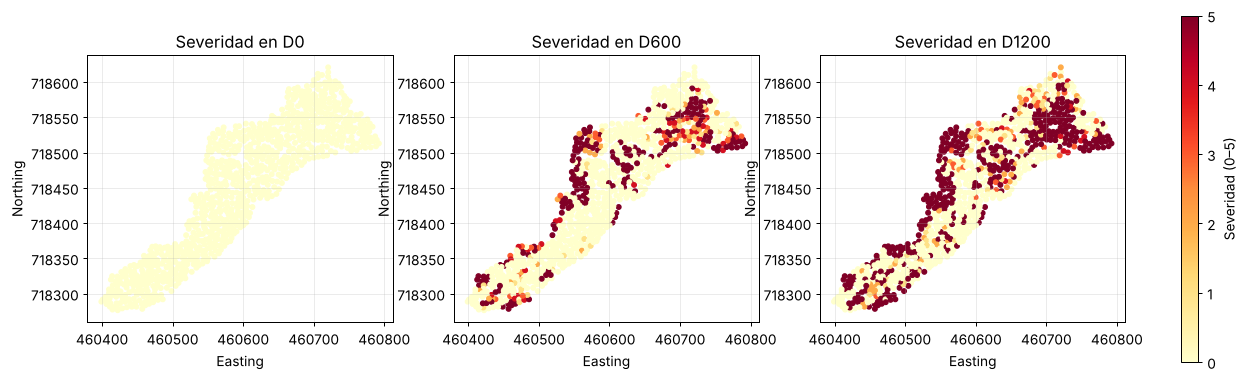

In [ ]:
# Mapa de la epidemia en tres momentos
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,tcol in zip(axes,['D0','D600','D1200']):
    v=d1[tcol].fillna(0).values
    sc=ax.scatter(XY[:,0],XY[:,1],c=v,cmap="YlOrRd",s=14,vmin=0,vmax=5)
    ax.set_title(f"Severidad en {tcol}"); ax.set_xlabel("Easting"); ax.set_ylabel("Northing")
    ax.set_aspect('equal')
fig.colorbar(sc,ax=axes,fraction=0.02,label="Severidad (0–5)")
plt.show()


In [ ]:
# k-NN espacial: predecir el estado de una planta por sus vecinos (proxy de dispersión local)
pred_vec = np.array([np.round(estado_final[idx[i]].mean()) for i in range(len(estado_final))])
acc = np.mean((pred_vec>=1)==(enfermo==1))
print(f"Exactitud de predicción por vecindad (dispersión local): {acc:.3f}")

# Métricas del componente espacial
m_esp = {"Autocorr_obs":round(same_disease,3),"Autocorr_esp":round(esperado,3),
         "p_valor":round(pval,3),"Exactitud_kNN":round(acc,3)}
print("Métricas espaciales:", m_esp)


Exactitud de predicción por vecindad (dispersión local): 0.609
Métricas espaciales: {'Autocorr_obs': np.float64(0.365), 'Autocorr_esp': np.float64(0.276), 'p_valor': np.float64(0.005), 'Exactitud_kNN': np.float64(0.609)}


### Práctica 3 — Explora la escala espacial
**Lo que debes hacer:** cambia `K` (nº de vecinos) a 4, 8 y 12; observa cómo cambia la autocorrelación.
Repite el mapa para *El Retiro-L2*. ¿Los focos coinciden con zonas bajas (encharcamiento)?


,Lote,K,Dist_media_vecino_K (m),Obs (BB),Esperado,Razón obs/esp,z,p
0,Donmatias-L1,4,7.8,0.368,0.276,1.34,15.1,0.001
1,Donmatias-L1,6,9.7,0.365,0.276,1.32,17.9,0.001
2,Donmatias-L1,8,11.4,0.356,0.276,1.29,18.3,0.001
3,Donmatias-L1,12,13.9,0.346,0.276,1.26,18.7,0.001
4,El Retiro-L2,4,7.0,0.491,0.271,1.81,43.8,0.001
5,El Retiro-L2,6,9.0,0.488,0.271,1.80,52.1,0.001
6,El Retiro-L2,8,10.4,0.485,0.271,1.79,60.3,0.001
7,El Retiro-L2,12,12.3,0.478,0.271,1.77,71.0,0.001
8,La Ceja-L3,4,6.2,0.507,0.292,1.74,47.3,0.001
9,La Ceja-L3,6,8.1,0.501,0.292,1.72,56.9,0.001


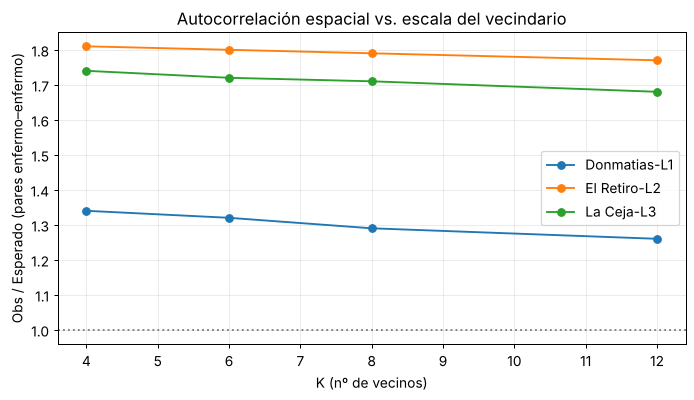

In [ ]:
# SOLUCIÓN Práctica 3 — Escala espacial (K = 4, 6, 8, 12) en los 3 lotes
def join_count(XY, enfermo, K, nperm=999, seed=1):
    tree = cKDTree(XY)
    _, idx = tree.query(XY, k=K + 1); idx = idx[:, 1:]
    e = enfermo.astype(bool)
    obs = np.mean(e[:, None] & e[idx])                      # pares vecinos ambos enfermos
    rng = np.random.default_rng(seed)
    perm = np.array([np.mean(ep[:, None] & ep[idx]) for ep in (rng.permutation(e) for _ in range(nperm))])
    z = (obs - perm.mean()) / perm.std()
    p = (np.sum(perm >= obs) + 1) / (nperm + 1)
    return obs, e.mean() ** 2, z, p, idx

res_k = []
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    XYl = d[['Easting', 'Northing']].values
    enf = (d['D1200'].fillna(0).values >= 1).astype(int)
    for K in [4, 6, 8, 12]:
        obs, esp, z, p, idx = join_count(XYl, enf, K)
        dist_k = cKDTree(XYl).query(XYl, k=K + 1)[0][:, -1].mean()
        res_k.append({"Lote": lote, "K": K, "Dist_media_vecino_K (m)": round(dist_k, 1),
                      "Obs (BB)": round(obs, 3), "Esperado": round(esp, 3),
                      "Razón obs/esp": round(obs / esp, 2), "z": round(z, 1), "p": round(p, 3)})
tabla_k = pd.DataFrame(res_k)
display(tabla_k)

plt.figure(figsize=(9, 4.5))
for lote in LOTES:
    t = tabla_k[tabla_k.Lote == lote]
    plt.plot(t["K"], t["Razón obs/esp"], "o-", label=lote)
plt.axhline(1, color="grey", ls=":"); plt.xlabel("K (nº de vecinos)"); plt.ylabel("Obs / Esperado (pares enfermo–enfermo)")
plt.title("Autocorrelación espacial vs. escala del vecindario"); plt.legend(); plt.show()

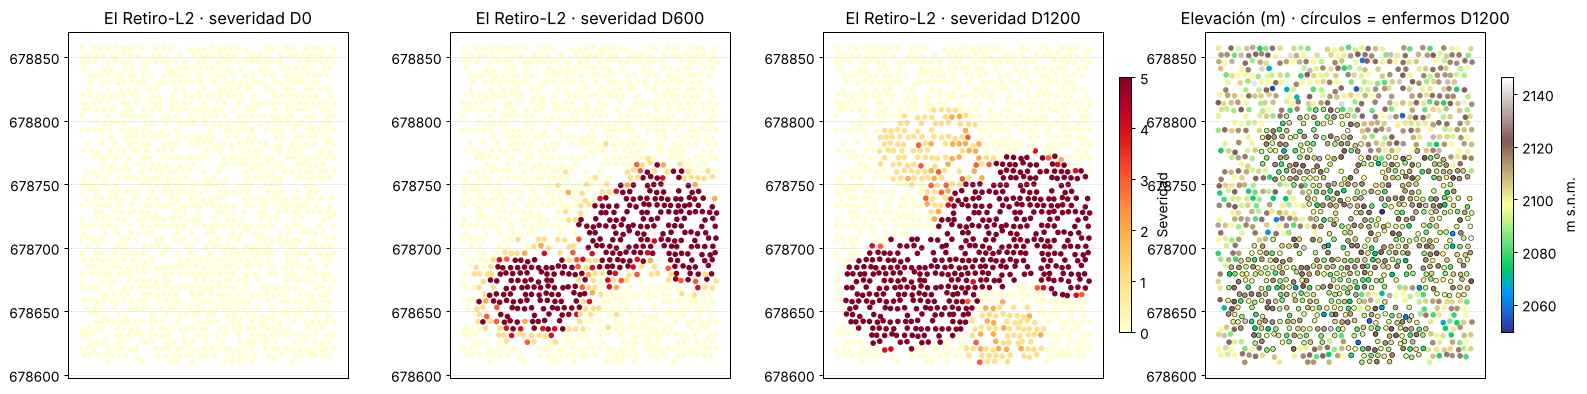

Lote,Donmatias-L1,El Retiro-L2,La Ceja-L3
Elev. media enfermos,2309.5,2101.7000,2389.4000
Elev. media sanos,2316.9,2104.8000,2390.6000
p (Mann-Whitney elev.),0.0,0.0001,0.1810
Incid. Q1 (más bajo) %,58.8,60.1000,56.2000
Incid. Q2 %,71.7,52.1000,54.9000
Incid. Q3 %,38.5,51.7000,52.4000
Incid. Q4 (más alto) %,40.9,44.2000,52.5000
Incid. Depresión (TPI) %,58.1,53.6000,54.9000
Incid. Plano (TPI) %,58.5,51.1000,53.0000
Incid. Loma (TPI) %,40.9,51.3000,54.2000


In [ ]:
# SOLUCIÓN Práctica 3 (cont.) — Mapa de El Retiro-L2 y relación con la topografía (GPS_Height)
d2, Dc2 = cargar_lote('El Retiro-L2')
XY2 = d2[['Easting', 'Northing']].values
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
for ax, tcol in zip(axes[:3], ['D0', 'D600', 'D1200']):
    sc = ax.scatter(XY2[:, 0], XY2[:, 1], c=d2[tcol].fillna(0), cmap="YlOrRd", s=12, vmin=0, vmax=5)
    ax.set_title(f"El Retiro-L2 · severidad {tcol}"); ax.set_aspect('equal'); ax.set_xticks([])
fig.colorbar(sc, ax=axes[2], fraction=0.04, label="Severidad")
sc2 = axes[3].scatter(XY2[:, 0], XY2[:, 1], c=d2['GPS_Height'], cmap="terrain", s=12)
enf2 = d2['D1200'].fillna(0).values >= 1
axes[3].scatter(XY2[enf2, 0], XY2[enf2, 1], facecolors='none', edgecolors='k', s=14, lw=0.4)
axes[3].set_title("Elevación (m) · círculos = enfermos D1200"); axes[3].set_aspect('equal'); axes[3].set_xticks([])
fig.colorbar(sc2, ax=axes[3], fraction=0.04, label="m s.n.m.")
plt.show()

# ¿Los focos están en zonas bajas? -> elevación absoluta y posición topográfica relativa (TPI)
from scipy.stats import mannwhitneyu
topo = []
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    XYl = d[['Easting', 'Northing']].values; h = d['GPS_Height'].values
    vec = cKDTree(XYl).query_ball_point(XYl, r=20)
    tpi = np.array([h[i] - h[v].mean() for i, v in enumerate(vec)])   # <0 = depresión local
    enf = d['D1200'].fillna(0).values >= 1
    q = pd.qcut(h, 4, labels=["Q1 (más bajo)", "Q2", "Q3", "Q4 (más alto)"])
    inc_q = pd.Series(enf).groupby(q, observed=True).mean() * 100
    tq = pd.qcut(tpi, 3, labels=["Depresión", "Plano", "Loma"])
    inc_t = pd.Series(enf).groupby(tq, observed=True).mean() * 100
    topo.append({"Lote": lote,
                 "Elev. media enfermos": round(h[enf].mean(), 1), "Elev. media sanos": round(h[~enf].mean(), 1),
                 "p (Mann-Whitney elev.)": round(mannwhitneyu(h[enf], h[~enf]).pvalue, 4),
                 **{f"Incid. {k} %": round(v, 1) for k, v in inc_q.items()},
                 **{f"Incid. {k} (TPI) %": round(v, 1) for k, v in inc_t.items()},
                 "p (Mann-Whitney TPI)": round(mannwhitneyu(tpi[enf], tpi[~enf]).pvalue, 4)})
tabla_topo = pd.DataFrame(topo).set_index("Lote").T
tabla_topo

### <font color="green">**Resultado Práctica 3**</font>  
- **Escala del vecindario:** en los tres lotes la proporción de pares vecinos enfermo–enfermo supera mucho lo esperado al azar (p = 0.001 para todos los K).
  - La razón observado/esperado es máxima con K = 4 (vecinos a ≈ 6–8 m) y baja levemente al ampliar el vecindario: L1 pasa de 1.34 a 1.26, L2 de 1.81 a 1.77 y L3 de 1.74 a 1.68.
  - La agregación es más fuerte entre vecinos inmediatos, como corresponde a un contagio raíz-raíz o por agua a pocos metros, pero se mantiene alta hasta ≈ 14 m. Esto indica focos más grandes que el vecindario evaluado.
  - El z sube con K porque hay más pares (más potencia estadística), no porque la agregación sea mayor.
- El Retiro-L2 y La Ceja-L3 están más agregados que Donmatías (razón ≈ 1.7–1.8 vs ≈ 1.3). El mapa de El Retiro muestra dos grandes focos compactos en el sur-centro en D600, que en D1200 se fusionan y crecen. En el norte y en el borde sur aparecen focos nuevos de grado bajo (1–2), probable dispersión a mayor distancia (escorrentía o tránsito).
- **¿Coinciden los focos con zonas bajas?** Parcialmente sí.
  - **Donmatías-L1:** los enfermos están en promedio 7 m más abajo (2309.5 vs 2316.9 m, p < 0.001). La incidencia es 59–72% en la mitad baja del lote frente a 39–41% en la mitad alta, y las depresiones y zonas planas (TPI) tienen 58% frente a 41% en las lomas (p < 0.001).
  - **El Retiro-L2:** el cuartil más bajo tiene 60% de incidencia y el más alto 44% (p = 0.0001), pero el TPI local no es significativo. La relación es con la posición en la ladera (parte baja del lote, donde se acumula el agua de escorrentía), no con hondonadas pequeñas.
  - **La Ceja-L3:** no hay relación con la elevación (p = 0.18).
  - Limitación: la cota viene del GPS (`Vert_Prec` con mediana ≈ 1 m, pero hasta 16 m en algunos puntos). Para confirmarlo convendría usar un DEM o un levantamiento topográfico.

### <font color="green">**Preguntas teóricas — Bloque 3 (Espacial)**</font>

**1. ¿Por qué un modelo espacial es más apropiado que uno global para un patógeno de suelo?**

*P. cinnamomi* no viaja por el aire a grandes distancias: se mueve con zoosporas en el agua del suelo, por contacto e injertos de raíces y por suelo arrastrado. La probabilidad de infección depende de qué tan cerca está un árbol enfermo. Un modelo global ignora eso, sobreestima la velocidad y no puede decir dónde aparecerán los próximos casos. El modelo espacial sí representa el avance como frentes que crecen desde focos, como se ve en los mapas.

**2. ¿Qué significa una autocorrelación espacial positiva en términos de dispersión de P. cinnamomi?**

Que los árboles enfermos tienen vecinos enfermos más a menudo de lo esperable por azar: la enfermedad está agregada en focos. Para *P. cinnamomi* indica dispersión por contagio local (planta a planta o por agua) y/o heterogeneidad ambiental, como parches de suelo mal drenado donde el patógeno prospera. Ambas cosas pueden actuar a la vez y la autocorrelación sola no las separa. Por eso se agregan covariables como la topografía, que en L1 y L2 explica parte del patrón.

**3. ¿Cómo influye la definición del vecindario (radio vs. k vecinos) en las conclusiones?**

El vecindario define la escala a la que se mide la agregación:
- Muy pequeño: pocos pares, mucha varianza, y puede quedar fuera la escala real del proceso. A 8 m, la red de Donmatías incluso se fragmenta.
- Muy grande: mezcla vecinos de dentro y fuera del foco y diluye la señal (la razón obs/esp baja con K).
- Radio vs. k vecinos: el radio fijo da a cada árbol un número de vecinos que depende de la densidad de siembra (en los bordes quedan con pocos). Los k vecinos dan siempre el mismo número de vecinos, pero a distancias variables.

Las conclusiones (p. ej., "hay focos de X m") dependen de esta elección. Lo correcto es evaluar varias escalas, como en esta práctica, o usar correlogramas o la función K de Ripley.

**4.Si detectas focos, ¿qué medidas de manejo espacialmente dirigidas recomendarías?**
- Delimitar los focos (con un "anillo" de 1–2 hileras de árboles aparentemente sanos alrededor) y tratarlos con prioridad: fosfito de potasio en inyección o aspersión, metalaxil al suelo.
- Drenaje en los focos y en las zonas bajas: zanjas, camellones, corrección de encharcamientos.
- Barreras físicas: zanjas de corte de escorrentía y raíces entre el foco y la zona sana.
- Cuarentena interna: no pasar maquinaria ni personal del foco a la zona sana, lavar y desinfectar herramientas y calzado, trabajar de lo sano a lo enfermo.
- Erradicación de árboles muertos (grado 5), con tratamiento del hoyo y sin resembrar con patrón susceptible.
- Muestreo dirigido con mayor intensidad en el borde de los focos (frente de avance) y en las zonas bajas.

**5. ¿Qué papel juega la topografía y el drenaje en la dispersión local de este oomiceto?**

Son determinantes porque el patógeno necesita agua libre: las zoosporas solo nadan y se dispersan en suelo saturado. El agua de escorrentía y el flujo subsuperficial arrastran el inóculo pendiente abajo, y en las zonas bajas, cóncavas o mal drenadas el suelo pasa más tiempo saturado, lo que además estresa las raíces por falta de oxígeno y las vuelve más susceptibles. Por eso los focos tienden a seguir la pendiente y a concentrarse abajo, como se observó en Donmatías y El Retiro. La topografía puede usarse como covariable de riesgo para priorizar muestreo y drenaje.

---
## 4. Modelo Basado en Agentes (Agent-Based Model, ABM)

### Estructura matemática / algorítmica
En un ABM no hay una ecuación global: cada **árbol es un agente** con un **estado** (S, I, R) y **reglas
locales** de transición. La dinámica **emerge** de las interacciones individuales.

**Regla de infección (por paso de tiempo Δt):** un árbol susceptible $i$ se infecta con probabilidad
$$P(S_i \to I_i) = 1 - \prod_{j \in \mathcal{N}(i),\, I_j=1} (1 - p_{ij}), \qquad p_{ij}=p_0\, e^{-d_{ij}/\lambda}$$
donde $p_0$ = probabilidad base de contagio, $d_{ij}$ = distancia, $\lambda$ = escala de dispersión.

**Regla de remoción:** un árbol infectado pasa a removido con probabilidad $p_R$ por paso.

### Asunciones
1. **Heterogeneidad individual**: cada agente puede tener sus propias reglas/atributos.
2. Contagio **local y estocástico** (probabilístico), dependiente de la distancia.
3. El sistema es **discreto** en el tiempo (pasos) y en los individuos.

###  ¿Qué preguntas resuelve?
- ¿Cómo emergen los **patrones espaciales** (focos) a partir de reglas simples?
- ¿Qué pasa si varío la **distancia de dispersión** $\lambda$ o la probabilidad $p_0$?
- ¿Cuál es la **variabilidad** entre epidemias (múltiples corridas estocásticas)?

###  ¿Para qué y cuándo se usa?
Cuando importa la **heterogeneidad individual**, la **estocasticidad** y los **patrones emergentes**;
ideal para **simular escenarios de manejo** (eliminar árboles, barreras) y evaluar su efecto.

### Requisitos de datos
Coordenadas de cada árbol + estado inicial. Los parámetros ($p_0$, $\lambda$, $p_R$) se **calibran**.


In [ ]:
# ABM sobre las posiciones REALES de los árboles del lote
d1,Dcols = cargar_lote('Donmatias-L1')
XY = d1[['Easting','Northing']].values
N = len(XY)
tree = cKDTree(XY)

def abm_prr(XY, tree, estado_inicial, p0=0.35, lam=8.0, pR=0.06, pasos=20, radio=15, seed=0):
    rng = np.random.default_rng(seed)
    state = estado_inicial.copy().astype(int)   # 0=S, 1=I, 2=R
    hist = [ (state==1).mean() + (state==2).mean() ]  # incidencia acumulada
    for _ in range(pasos):
        new = state.copy()
        infectados = np.where(state==1)[0]
        for i in np.where(state==0)[0]:               # susceptibles
            vecinos = tree.query_ball_point(XY[i], r=radio)
            inf_v = [j for j in vecinos if state[j]==1]
            if inf_v:
                d = np.linalg.norm(XY[inf_v]-XY[i], axis=1)
                p = p0*np.exp(-d/lam)
                if rng.random() < (1 - np.prod(1-p)):
                    new[i] = 1
        for i in infectados:                          # remoción
            if rng.random() < pR: new[i] = 2
        state = new
        hist.append( (state==1).mean() + (state==2).mean() )
    return state, np.array(hist)

# estado inicial: los enfermos en D60 como semilla
sem = (d1['D60'].fillna(0).values>=1).astype(int)   # 1 si enfermo
estado0 = np.where(sem==1, 1, 0)
final_state, hist = abm_prr(XY, tree, estado0, seed=1)
print(f"Incidencia final simulada (1 corrida): {hist[-1]*100:.1f}%")


Incidencia final simulada (1 corrida): 100.0%


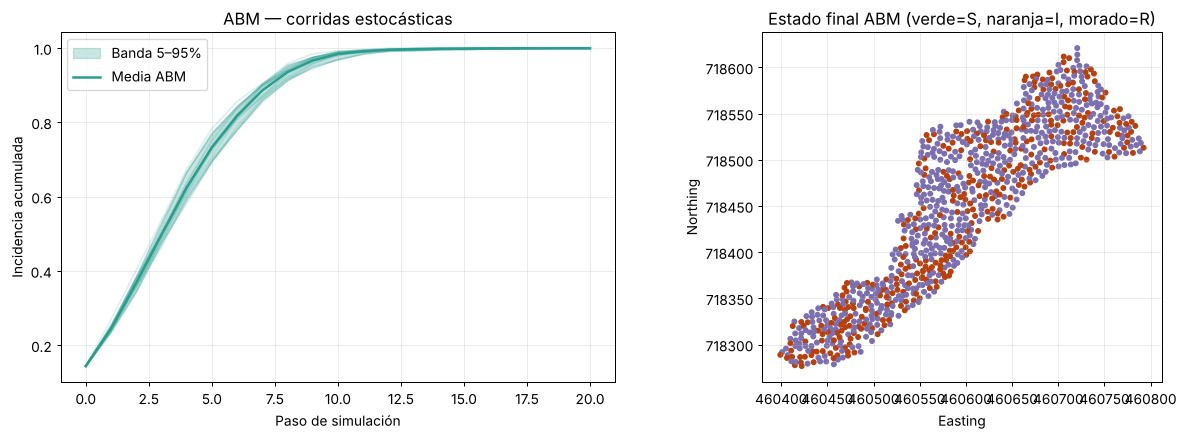

In [ ]:
# Múltiples corridas estocásticas -> banda de incertidumbre
corridas = np.array([abm_prr(XY,tree,estado0,seed=s)[1] for s in range(15)])
media = corridas.mean(0); lo,hi = np.percentile(corridas,[5,95],axis=0)
pasos = np.arange(corridas.shape[1])

# comparar con incidencia real
inc_real = np.array([(d1[c]>=1).mean() for c in Dcols])

fig,ax=plt.subplots(1,2,figsize=(14,5))
for c in corridas: ax[0].plot(pasos, c, color=C_FIT, alpha=0.15)
ax[0].fill_between(pasos, lo, hi, color=C_FIT, alpha=0.25, label="Banda 5–95%")
ax[0].plot(pasos, media, color=C_FIT, lw=2, label="Media ABM")
ax[0].set_xlabel("Paso de simulación"); ax[0].set_ylabel("Incidencia acumulada"); ax[0].set_title("ABM — corridas estocásticas"); ax[0].legend()

# mapa final del ABM
cmap={0:"#2A9D8F",1:"#B7410E",2:"#7B6FB0"}
cols=[cmap[v] for v in final_state]
ax[1].scatter(XY[:,0],XY[:,1],c=cols,s=14); ax[1].set_aspect('equal')
ax[1].set_title("Estado final ABM (verde=S, naranja=I, morado=R)"); ax[1].set_xlabel("Easting"); ax[1].set_ylabel("Northing")
plt.tight_layout(); plt.show()


In [ ]:
# Métricas del ABM (ajuste al patrón real de incidencia + complejidad)
# Interpolamos la media del ABM a los tiempos reales para comparar
from numpy import interp
abm_en_tiempos = interp(np.linspace(0,pasos[-1],len(times)), pasos, media)
m_abm = metricas_modelo(inc_real, abm_en_tiempos, k=3)  # p0, lam, pR
print("Métricas ABM (vs incidencia real):")
print("  Ajuste     → R² =", m_abm["R2"])
print("  Error      → RMSE =", m_abm["RMSE"], "| MAE =", m_abm["MAE"])
print("  Complejidad→ 3 parámetros calibrables (p0, λ, pR) + estocasticidad")
pd.DataFrame([m_abm])


Métricas ABM (vs incidencia real):
  Ajuste     → R² = -14.124
  Error      → RMSE = 0.5214 | MAE = 0.4939
  Complejidad→ 3 parámetros calibrables (p0, λ, pR) + estocasticidad


,R2,RMSE,MAE,AIC,AICc,BIC,k_params
0,-14.124,0.5214,0.4939,-21.3,-19.9,-18.2,3


### Práctica 4 — Escenarios de manejo con el ABM
**Lo que debes hacer:**
- Varía `lam` (distancia de dispersión) a 4, 8 y 16. ¿Cómo cambia la velocidad de la epidemia?
- **Simula una medida de manejo:** elimina (pon en estado R) el 20% de árboles más conectados antes de
  iniciar y compara la incidencia final. ¿Funciona como barrera?


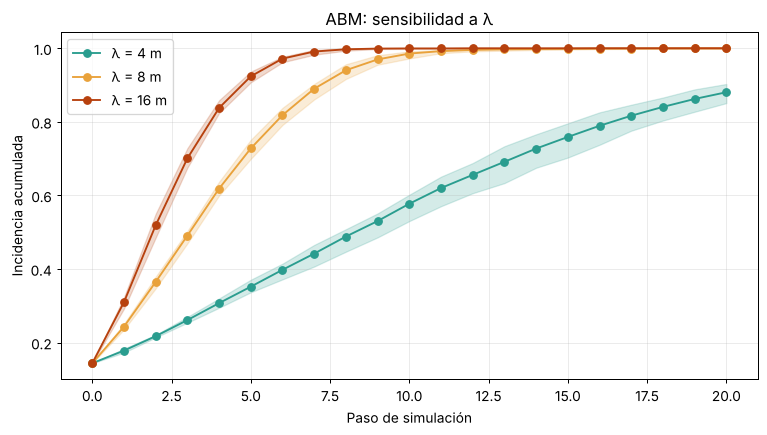

,λ (m),Incid. final media %,Paso en que supera 50%,"Tasa media (pp/paso, 5 primeros)"
0,4,88.0,9,4.16
1,8,100.0,4,11.67
2,16,100.0,2,15.59


In [ ]:
# SOLUCIÓN Práctica 4a — Efecto de la escala de dispersión λ (4, 8, 16 m)
NRUN = 8
curvas_lam = {}
for lam in [4, 8, 16]:
    runs = np.array([abm_prr(XY, tree, estado0, lam=lam, seed=s)[1] for s in range(NRUN)])
    curvas_lam[lam] = runs
res_lam = []
plt.figure(figsize=(10, 5))
for (lam, runs), col in zip(curvas_lam.items(), [C_FIT, C_ALT, C_OBS]):
    m = runs.mean(0); lo, hi = np.percentile(runs, [5, 95], axis=0)
    plt.fill_between(pasos, lo, hi, color=col, alpha=0.2); plt.plot(pasos, m, "o-", color=col, label=f"λ = {lam} m")
    t50 = np.argmax(m >= 0.5) if (m >= 0.5).any() else np.nan
    res_lam.append({"λ (m)": lam, "Incid. final media %": round(m[-1] * 100, 1),
                    "Paso en que supera 50%": t50, "Tasa media (pp/paso, 5 primeros)": round(np.diff(m[:6]).mean() * 100, 2)})
plt.xlabel("Paso de simulación"); plt.ylabel("Incidencia acumulada"); plt.title("ABM: sensibilidad a λ"); plt.legend(); plt.show()
pd.DataFrame(res_lam)

Mejor combinación: p0=0.04, λ=8 m  →  R²=0.455, RMSE=0.0853


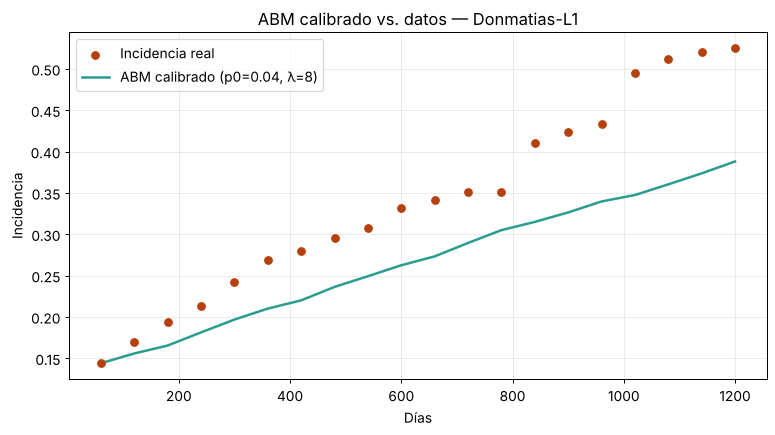

,p0,λ,RMSE
5,0.04,8,0.0853
7,0.08,8,0.1176
6,0.08,4,0.1458
3,0.02,8,0.1656
4,0.04,4,0.1950
1,0.01,8,0.2030
2,0.02,4,0.2095
0,0.01,4,0.2211


In [ ]:
#Calibración básica del ABM (alinear pasos con fechas reales)
# El ABM original arranca en D60 y cada paso = 60 días, pero se comparó contra la serie desde D0 y con p0
# muy alto (satura al 100%). Aquí: paso k ↔ día 60+60k y búsqueda en malla de p0 y λ.
t_real = times[1:]                                 # D60..D1200 (20 tiempos) ↔ pasos 0..19
y_real = inc_real[1:]
malla = []
for p0 in [0.01, 0.02, 0.04, 0.08]:
    for lam in [4, 8]:
        runs = np.array([abm_prr(XY, tree, estado0, p0=p0, lam=lam, pR=0.06, pasos=19, seed=s)[1] for s in range(3)])
        rmse = np.sqrt(np.mean((runs.mean(0) - y_real) ** 2))
        malla.append({"p0": p0, "λ": lam, "RMSE": round(rmse, 4), "curva": runs.mean(0)})
malla_df = pd.DataFrame(malla).sort_values("RMSE")
mejor = malla_df.iloc[0]
m_abm_cal = metricas_modelo(y_real, mejor["curva"], k=3)
print(f"Mejor combinación: p0={mejor['p0']}, λ={mejor['λ']} m  →  R²={m_abm_cal['R2']}, RMSE={m_abm_cal['RMSE']}")
plt.figure(figsize=(10, 5))
plt.scatter(t_real, y_real, color=C_OBS, zorder=3, label="Incidencia real")
plt.plot(t_real, mejor["curva"], color=C_FIT, lw=2, label=f"ABM calibrado (p0={mejor['p0']}, λ={mejor['λ']})")
plt.xlabel("Días"); plt.ylabel("Incidencia"); plt.title("ABM calibrado vs. datos — Donmatias-L1"); plt.legend(); plt.show()
malla_df.drop(columns="curva").head(8)

Semillas (enfermos D60) retiradas → top20%: 4 · azar: 21 · focos+anillo: 130
Conectividad (vecinos a ≤15 m): media=14.3; el top 20% tiene ≥17 vecinos


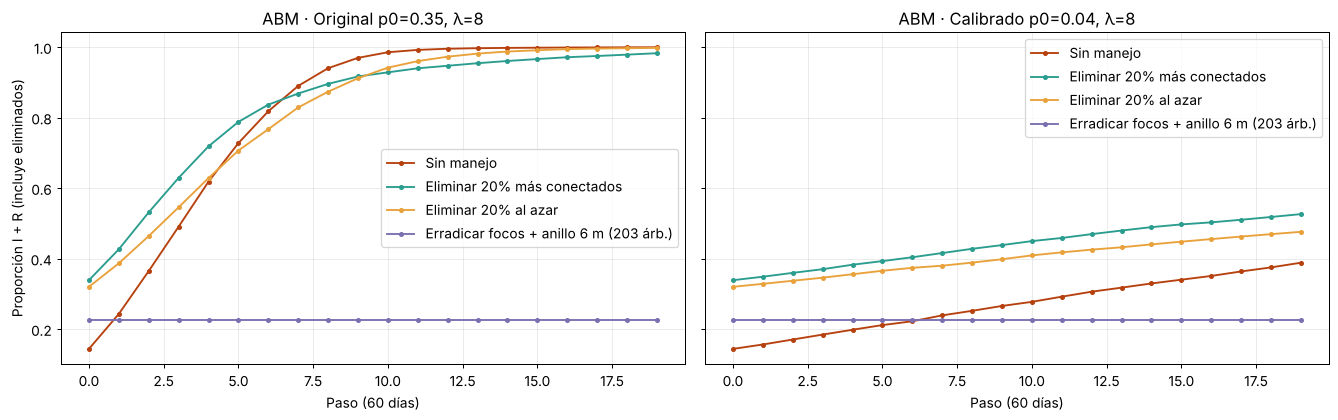

,Parámetros,Escenario,Eliminados,Sanos expuestos,Nuevas infecciones,% de expuestos que se infecta
0,"Original p0=0.35, λ=8",Sin manejo,0,773,773,100.0
1,"Original p0=0.35, λ=8",Eliminar 20% más conectados,180,597,581,97.4
2,"Original p0=0.35, λ=8",Eliminar 20% al azar,180,614,612,99.7
3,"Original p0=0.35, λ=8",Erradicar focos + anillo 6 m (203 árb.),203,700,0,0.0
4,"Calibrado p0=0.04, λ=8",Sin manejo,0,773,221,28.6
5,"Calibrado p0=0.04, λ=8",Eliminar 20% más conectados,180,597,169,28.4
6,"Calibrado p0=0.04, λ=8",Eliminar 20% al azar,180,614,141,22.9
7,"Calibrado p0=0.04, λ=8",Erradicar focos + anillo 6 m (203 árb.),203,700,0,0.0


In [ ]:
# SOLUCIÓN Práctica 4b — Manejo: eliminar el 20% de árboles MÁS CONECTADOS antes de iniciar
# Se compara contra eliminar 20% AL AZAR (control) y se evalúa con p0 original (0.35) y con p0 calibrado.
RAD_ABM = 15                                   # mismo radio de contacto que usa el ABM
n_vec = np.array([len(v) - 1 for v in tree.query_ball_point(XY, r=RAD_ABM)])   # conectividad de cada árbol
n20 = int(0.20 * N)
top20 = np.argsort(n_vec)[::-1][:n20]
azar20 = np.random.default_rng(7).choice(N, n20, replace=False)
# Erradicación de focos: árboles enfermos en D60 + todos sus vecinos a ≤ 6 m (anillo de seguridad)
focos = np.unique(np.concatenate([tree.query_ball_point(XY[i], r=6) for i in np.where(estado0 == 1)[0]]))
print(f"Semillas (enfermos D60) retiradas → top20%: {estado0[top20].sum()} · azar: {estado0[azar20].sum()} · focos+anillo: {estado0[focos].sum()}")
p0_cal, lam_cal = float(mejor["p0"]), float(mejor["λ"])

def escenario(eliminar, p0, lam, seeds=range(NRUN)):
    e0 = estado0.copy(); e0[eliminar] = 2      # eliminados -> R (no se infectan ni transmiten)
    runs = np.array([abm_prr(XY, tree, e0, p0=p0, lam=lam, pasos=19, seed=s)[1] for s in seeds])
    fuera = np.union1d(eliminar, np.where(estado0 == 1)[0]).size   # eliminados ∪ semillas
    en_riesgo = N - fuera
    nuevos = runs[:, -1] * N - fuera
    return runs, nuevos.mean(), nuevos.mean() / en_riesgo * 100, en_riesgo

res_m = []
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for a, (etq, p0_, lam_) in zip(ax, [("Original p0=0.35, λ=8", 0.35, 8.0), (f"Calibrado p0={p0_cal}, λ={lam_cal:g}", p0_cal, lam_cal)]):
    for (k, el), col in zip({"Sin manejo": np.array([], int), "Eliminar 20% más conectados": top20,
                             "Eliminar 20% al azar": azar20,
                             f"Erradicar focos + anillo 6 m ({len(focos)} árb.)": focos}.items(), [C_OBS, C_FIT, C_ALT, C_R]):
        runs, nuevos, pct, riesgo = escenario(el, p0_, lam_)
        a.plot(runs.mean(0), "o-", ms=3, color=col, label=k)
        res_m.append({"Parámetros": etq, "Escenario": k, "Eliminados": len(el), "Sanos expuestos": riesgo,
                      "Nuevas infecciones": round(nuevos), "% de expuestos que se infecta": round(pct, 1)})
    a.set_title(f"ABM · {etq}"); a.set_xlabel("Paso (60 días)"); a.legend()
ax[0].set_ylabel("Proporción I + R (incluye eliminados)")
plt.tight_layout(); plt.show()
print(f"Conectividad (vecinos a ≤{RAD_ABM} m): media={n_vec.mean():.1f}; el top 20% tiene ≥{n_vec[top20].min()} vecinos")
tabla_manejo = pd.DataFrame(res_m)
tabla_manejo

### <font color="green">**Resultado Práctica 4**</font>

**Efecto de λ.** A mayor escala de dispersión, la epidemia es mucho más rápida:
- con λ = 4 m supera el 50% de incidencia en el paso 9 y termina en ≈ 88%
- con λ = 8 m lo hace en el paso 4
- con λ = 16 m en el paso 2

Con λ ≥ 8 m se llega al 100%. La tasa inicial casi se cuadruplica (4.2 → 15.6 pp/paso). Nota: con λ = 16 m el efecto queda limitado por el `radio = 15 m` del código, que corta la dispersión.

**Calibración**:  El ABM original (p0 = 0.35) no representa los datos: satura al 100% en pocos pasos, cuando lo observado es 52.5% en D1200 (R² = −14). Además se comparaba con pasos desalineados. Alineando cada paso con 60 días desde D60 y buscando p0 y λ, el mejor ajuste es p0 = 0.04, λ = 8 m (R² = 0.46, RMSE = 0.085). El ABM calibrado reproduce la pendiente pero se queda corto al final (≈ 39% vs 52%). Le faltan los saltos a distancia que crean focos nuevos, como los que aparecen en el norte de El Retiro.

**Escenarios de manejo.** Medí el % de árboles sanos expuestos que llegan a infectarse, porque si los eliminados se cuentan como "R" la incidencia parece subir.
- Eliminar el 20% de árboles más conectados NO funciona como barrera. Con los parámetros originales el resultado pasa de 100% a 97.4%, y con los calibrados de 28.6% a 28.4%, prácticamente igual que no hacer nada. Incluso es peor que eliminar el 20% al azar (22.9%).
  - Porque en una plantación en marco regular todos los árboles tienen casi el mismo número de vecinos (14 en promedio, y el top 20% tiene ≥ 17). Los "más conectados" son solo los de zonas de siembra más densa y casi no incluyen enfermos: retiran 4 de las 130 semillas, contra 21 al azar.
- Erradicar los focos (enfermos en D60 + anillo de 6 m, 203 árboles) detiene la epidemia en el modelo (0 nuevas infecciones). Es un límite optimista: el ABM no tiene inóculo residual en el suelo ni infecciones latentes sin síntomas, que en la realidad mantienen viva la PRR después de arrancar los árboles.
- La intervención debe dirigirse a dónde está la enfermedad (focos y su frente de avance), no a la conectividad geométrica.

### <font color="green">**Preguntas teóricas — Bloque 4 (ABM)**</font>






**1. ¿Qué ventaja tiene un ABM sobre un modelo compartimental para representar P. cinnamomi?**

Representa cada árbol en su posición real con su propio estado e historia, así que incorpora de forma natural la dispersión local dependiente de la distancia, la heterogeneidad(portainjerto, edad, microtopografía, drenaje de cada sitio) y la estocasticidad. Los focos emergen de reglas simples. Además permite simular intervenciones concretas ("arrancar estos 50 árboles", "barrera en esta hilera") que un SIR global no puede expresar, porque solo conoce proporciones.

**2. ¿Por qué el ABM produce una banda de incertidumbre y el SIR determinístico no?**

El SIR es determinístico: con los mismos parámetros y condiciones iniciales siempre da la misma curva. El ABM es estocástico: en cada paso cada infección y cada remoción se sortea (`rng.random() < p`), de modo que cada corrida es una realización distinta del proceso. Al repetirlo muchas veces se obtiene una distribución de epidemias posibles, y la banda del 5–95% expresa el azar propio de la transmisión. Esto es importante con pocos focos iniciales, donde la suerte decide si un foco se extingue o explota. (Un SIR también puede tener bandas, pero de incertidumbre en los parámetros, no del proceso.)

**3. ¿Qué representa el parámetro  λ  (escala de dispersión) en la biología del patógeno?**: con p = p0·e^(−d/λ), a una distancia d = λ la probabilidad cae al 37% de p0. Biológicamente resume qué tan lejos llega efectivamente el inóculo: la extensión del sistema de raíces y los injertos radiculares, la distancia que recorren las zoosporas en el agua del suelo y el arrastre por escorrentía o por pendiente. Un λ mayor indica suelos más húmedos y conectados por agua o pendientes que favorecen el arrastre. Las prácticas culturales que mueven suelo también lo agrandan en la práctica.

**4. ¿Cómo usarías un ABM para evaluar la erradicación de focos o barreras físicas?**
1. Calibrar p0, λ y pR con los datos históricos del lote, como en la celda de calibración.
2. Definir los escenarios: eliminar los enfermos más un anillo de r metros (probando r = 0, 3, 6, 9 m), eliminar solo los grado 5, o poner una barrera. La barrera se modela anulando p_ij para los pares de árboles que cruzan una línea (zanja) o reduciendo λ en una franja drenada.
3. Correr muchas réplicas estocásticas por escenario y comparar la distribución de: nuevas infecciones, área afectada, tiempo hasta el 50% y probabilidad de extinción del foco.
4. Calcular el costo-beneficio: árboles sacrificados frente a árboles salvados.
5. Hacer un análisis de sensibilidad: ¿la recomendación cambia si λ o p0 son distintos?

Es lo que se hizo en la práctica con el escenario "focos + anillo 6 m". Para que sea realista habría que agregar el inóculo residual en el suelo de los árboles eliminados.

**5. ¿Qué limita el uso de ABM en la práctica (datos, cómputo, calibración)?**
- **Datos:** requiere coordenadas y estados individuales a lo largo del tiempo, y para que sea realista, covariables por árbol (suelo, drenaje, patrón) que pocas veces existen.
- **Calibración:** muchos parámetros que interactúan, sin verosimilitud cerrada. Hay que usar búsqueda en malla, ABC u optimización por simulación, con problemas de **identificabilidad** (varias combinaciones ajustan igual), como se vio con p0 y λ.
- **Cómputo:** con bucles por árbol, por paso y por réplica escala mal en lotes grandes o en análisis de sensibilidad.
- **Validación:** es difícil validar los patrones espaciales emergentes.
- **Comunicación:** es menos transparente que una ecuación y existe el riesgo de "parecer realista" sin estar bien calibrado. El ABM original de este taller daba R² = −14.

---
## 5. Modelo Compartimental con análisis de redes

### Estructura matemática
La plantación se representa como un **grafo** $G=(V,E)$: los **nodos** $V$ son árboles y las **aristas** $E$
conectan árboles que pueden **transmitirse** la enfermedad (p. ej. vecinos dentro de un radio). La epidemia
es un proceso **SIR sobre la red**:

$$
\frac{dI_i}{dt} = \beta\, S_i \sum_{j} A_{ij}\, I_j - \gamma\, I_i
$$
donde $A_{ij}$ es la **matriz de adyacencia** (1 si $i$–$j$ están conectados).

**Métricas de red clave:**
- **Grado** $k_i$: número de conexiones de un nodo (árboles muy conectados = súper-dispersores).
- **Grado medio** $\langle k \rangle$ y distribución de grado.
- **Centralidad** (betweenness, eigenvector): identifica nodos críticos para la propagación.
- **Umbral epidémico** en redes: $\;\tau_c \approx \dfrac{\langle k \rangle}{\langle k^2 \rangle}$
  (relacionado con $\beta/\gamma$). Redes heterogéneas → umbral más bajo → epidemias más fáciles.

### Asunciones
1. La transmisión ocurre **solo por aristas** (contactos definidos por proximidad).
2. La **topología** de la red gobierna la dispersión (no la mezcla homogénea).
3. La estructura de contactos es **estática** (puede extenderse a dinámica).

### ¿Qué preguntas resuelve?
- ¿Qué árboles son **críticos** (hubs) para la propagación?
- ¿La estructura de la plantación **facilita o frena** la epidemia (umbral)?
- ¿Dónde intervenir (**vacunación/eliminación dirigida**) para fragmentar la red?

### ¿Para qué y cuándo se usa?
Cuando la **estructura de contactos** es heterogénea y se busca **priorizar intervenciones**
(eliminar/proteger los nodos más centrales). Muy útil para **manejo dirigido**.

### Requisitos de datos
Coordenadas de árboles (para construir la red por proximidad) + estados.


In [ ]:
# Construir la red de proximidad (radio de contacto) sobre el lote
d1,Dcols = cargar_lote('Donmatias-L1')
XY = d1[['Easting','Northing']].values
RADIO = 12  # metros: distancia máxima de "contacto" para transmisión

tree = cKDTree(XY)
pares = tree.query_pairs(r=RADIO)          # todas las parejas dentro del radio
G = nx.Graph()
G.add_nodes_from(range(len(XY)))
G.add_edges_from(pares)

grados = np.array([d for _,d in G.degree()])
k_mean = grados.mean(); k2_mean = (grados**2).mean()
umbral = k_mean/k2_mean if k2_mean>0 else np.nan
print(f"Red: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas")
print(f"Grado medio <k> = {k_mean:.2f} | <k²> = {k2_mean:.1f}")
print(f"Umbral epidémico aprox τc = <k>/<k²> = {umbral:.4f}")
print("→ Cuanto menor τc, más vulnerable es la plantación a epidemias")


Red: 903 nodos, 3992 aristas
Grado medio <k> = 8.84 | <k²> = 84.3
Umbral epidémico aprox τc = <k>/<k²> = 0.1048
→ Cuanto menor τc, más vulnerable es la plantación a epidemias


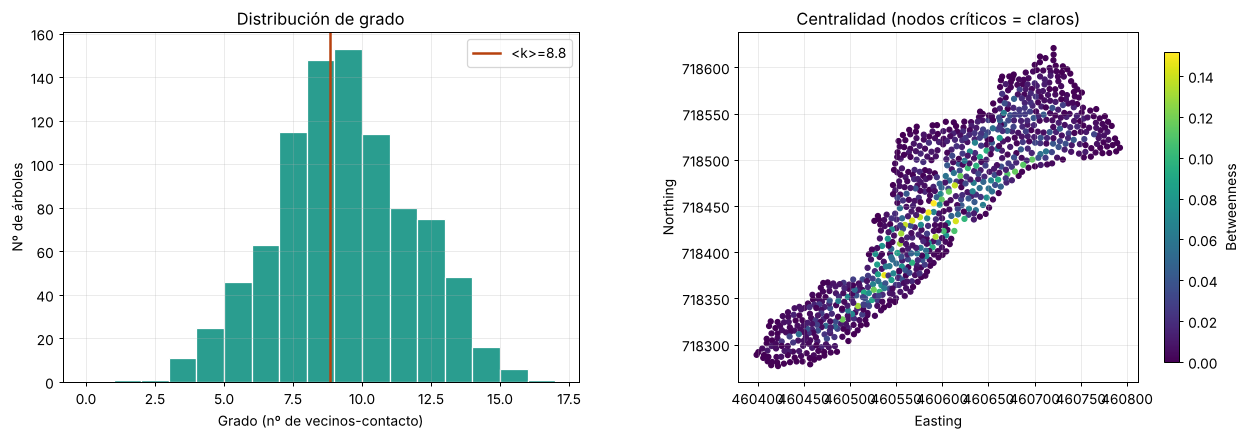

In [ ]:
# Distribución de grado + centralidad
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].hist(grados,bins=range(0,grados.max()+2),color=C_FIT,edgecolor="white")
ax[0].axvline(k_mean,color=C_OBS,lw=2,label=f"<k>={k_mean:.1f}")
ax[0].set_xlabel("Grado (nº de vecinos-contacto)"); ax[0].set_ylabel("Nº de árboles")
ax[0].set_title("Distribución de grado"); ax[0].legend()

# Betweenness (en submuestra para velocidad si la red es grande)
if G.number_of_nodes()<=1200:
    bc = nx.betweenness_centrality(G, k=min(100,G.number_of_nodes()), seed=1)
else:
    bc = nx.degree_centrality(G)
bc_arr = np.array([bc[i] for i in range(len(XY))])
sc=ax[1].scatter(XY[:,0],XY[:,1],c=bc_arr,cmap="viridis",s=16)
ax[1].set_title("Centralidad (nodos críticos = claros)"); ax[1].set_aspect('equal')
ax[1].set_xlabel("Easting"); ax[1].set_ylabel("Northing")
fig.colorbar(sc,ax=ax[1],fraction=0.03,label="Betweenness")
plt.tight_layout(); plt.show()


Incidencia final — base: 99.0%  |  intervención: 96.4%
Reducción: 2.6 puntos porcentuales


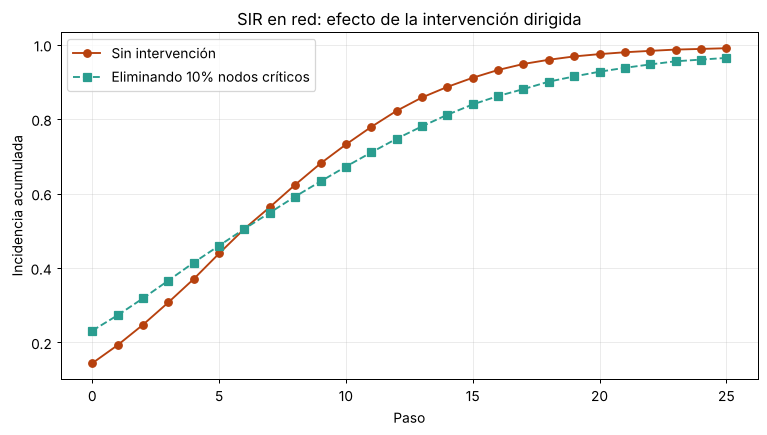

In [ ]:
# SIR SOBRE LA RED (simulación) y efecto de eliminar los nodos más centrales
def sir_red(G, estado0, beta=0.08, gamma=0.05, pasos=25, seed=0):
    rng=np.random.default_rng(seed)
    state=estado0.copy()   # 0=S,1=I,2=R
    A=[list(G.neighbors(i)) for i in range(G.number_of_nodes())]
    hist=[ (state>=1).mean() ]
    for _ in range(pasos):
        new=state.copy()
        for i in np.where(state==1)[0]:
            for j in A[i]:
                if state[j]==0 and rng.random()<beta: new[j]=1
            if rng.random()<gamma: new[i]=2
        state=new; hist.append((state>=1).mean())
    return np.array(hist)

estado0=np.where((d1['D60'].fillna(0).values>=1),1,0)

# escenario base
base=np.array([sir_red(G,estado0,seed=s) for s in range(10)]).mean(0)

# escenario intervención: eliminar (aislar) el 10% de nodos más centrales
n_remove=int(0.10*G.number_of_nodes())
criticos=sorted(bc,key=bc.get,reverse=True)[:n_remove]
G2=G.copy(); G2.remove_nodes_from(criticos)
# reindex para simular (mapa simple)
estado0b=estado0.copy();
for c in criticos: estado0b[c]=2   # los eliminados = removidos
interv=np.array([sir_red(G,estado0b,seed=s) for s in range(10)]).mean(0)

plt.figure(figsize=(10,5))
plt.plot(base,"o-",color=C_OBS,label="Sin intervención")
plt.plot(interv,"s--",color=C_FIT,label="Eliminando 10% nodos críticos")
plt.xlabel("Paso"); plt.ylabel("Incidencia acumulada"); plt.title("SIR en red: efecto de la intervención dirigida"); plt.legend(); plt.show()
print(f"Incidencia final — base: {base[-1]*100:.1f}%  |  intervención: {interv[-1]*100:.1f}%")
print(f"Reducción: {(base[-1]-interv[-1])*100:.1f} puntos porcentuales")


In [ ]:
# Métricas de la red y del proceso
m_red = {"Nodos":G.number_of_nodes(),"Aristas":G.number_of_edges(),
         "Grado_medio":round(k_mean,2),"Umbral_tc":round(umbral,4),
         "Densidad":round(nx.density(G),4),
         "Reduccion_intervencion_pp":round((base[-1]-interv[-1])*100,1)}
print("Métricas de red:")
pd.DataFrame([m_red])


Métricas de red:


,Nodos,Aristas,Grado_medio,Umbral_tc,Densidad,Reduccion_intervencion_pp
0,903,3992,8.84,0.1048,0.0098,2.6


### Práctica 5 — Diseña la intervención óptima
**Lo que debes hacer:**
- Cambia el `RADIO` de contacto (8, 12, 20 m) y observa cómo cambia el umbral epidémico.
- Compara eliminar nodos por **betweenness** vs. por **grado** vs. **al azar**. ¿Cuál reduce más la epidemia?


In [ ]:
#SOLUCIÓN Práctica 5a — Radio de contacto vs. umbral epidémico
res_r = []
for lote in LOTES:
    d, Dc = cargar_lote(lote)
    XYl = d[['Easting', 'Northing']].values
    for R_ in [8, 12, 20]:
        Gr = nx.Graph(); Gr.add_nodes_from(range(len(XYl))); Gr.add_edges_from(cKDTree(XYl).query_pairs(r=R_))
        g = np.array([k for _, k in Gr.degree()])
        res_r.append({"Lote": lote, "Radio (m)": R_, "Aristas": Gr.number_of_edges(),
                      "<k>": round(g.mean(), 2), "<k²>": round((g ** 2).mean(), 1),
                      "τc=<k>/<k²>": round(g.mean() / (g ** 2).mean(), 4) if g.any() else np.nan,
                      "Aislados": int((g == 0).sum()), "Componentes": nx.number_connected_components(Gr),
                      "Densidad": round(nx.density(Gr), 4)})
tabla_radio = pd.DataFrame(res_r)
tabla_radio

,Lote,Radio (m),Aristas,<k>,<k²>,τc=<k>/<k²>,Aislados,Componentes,Densidad
0,Donmatias-L1,8,1799,3.98,17.6,0.2260,5,7,0.0044
1,Donmatias-L1,12,3992,8.84,84.3,0.1048,0,1,0.0098
2,Donmatias-L1,20,11195,24.80,651.2,0.0381,0,1,0.0275
3,El Retiro-L2,8,3045,4.55,22.1,0.2061,1,2,0.0034
4,El Retiro-L2,12,7719,11.54,138.1,0.0835,0,1,0.0086
5,El Retiro-L2,20,20236,30.25,944.8,0.0320,0,1,0.0226
6,La Ceja-L3,8,4217,5.06,27.4,0.1850,1,2,0.0030
7,La Ceja-L3,12,11207,13.45,187.2,0.0719,0,1,0.0081
8,La Ceja-L3,20,31851,38.24,1508.3,0.0254,0,1,0.0230


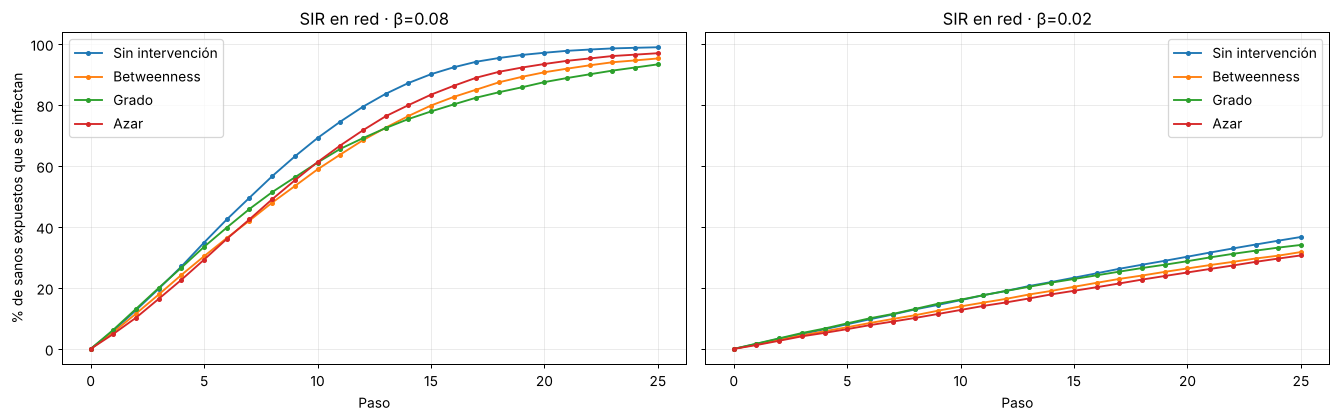

,β,Estrategia,Sanos expuestos,% expuestos infectados,±DE,Reducción vs base (pp)
0,0.08,Sin intervención,773,98.9,0.5,0.0
1,0.08,Betweenness,694,95.3,2.1,3.6
2,0.08,Grado,684,93.3,2.3,5.6
3,0.08,Azar,702,97.0,0.8,1.9
4,0.02,Sin intervención,773,36.7,2.6,0.0
5,0.02,Betweenness,694,31.8,2.4,4.9
6,0.02,Grado,684,34.1,3.1,2.6
7,0.02,Azar,702,30.7,3.0,6.0


In [ ]:
# SOLUCIÓN Práctica 5b — ¿Qué estrategia de eliminación reduce más la epidemia?
# Métrica justa: % de árboles SANOS NO ELIMINADOS que terminan infectados (los eliminados no cuentan como enfermos).
deg = dict(G.degree())
n_remove = int(0.10 * G.number_of_nodes())
estrategias = {
    "Sin intervención": [],
    "Betweenness": sorted(bc, key=bc.get, reverse=True)[:n_remove],
    "Grado": sorted(deg, key=deg.get, reverse=True)[:n_remove],
    "Azar": list(np.random.default_rng(3).choice(G.number_of_nodes(), n_remove, replace=False)),
}
Nn = G.number_of_nodes()
res_e, curvas_e = [], {}
for beta_ in [0.08, 0.02]:                       # β original (satura) y un β moderado
    for nombre, nodos in estrategias.items():
        e0 = estado0.copy(); e0[list(nodos)] = 2
        fuera = np.union1d(np.array(nodos, int), np.where(estado0 == 1)[0]).size
        runs = np.array([sir_red(G, e0, beta=beta_, seed=s) for s in range(20)])
        nuevos = runs[:, -1] * Nn - fuera
        pct = nuevos / (Nn - fuera) * 100
        curvas_e[(beta_, nombre)] = (runs.mean(0) * Nn - fuera) / (Nn - fuera) * 100
        res_e.append({"β": beta_, "Estrategia": nombre, "Sanos expuestos": Nn - fuera,
                      "% expuestos infectados": round(pct.mean(), 1), "±DE": round(pct.std(), 1)})
tabla_estr = pd.DataFrame(res_e)
for beta_ in [0.08, 0.02]:
    base_pct = tabla_estr.query("β==@beta_ and Estrategia=='Sin intervención'")["% expuestos infectados"].iloc[0]
    tabla_estr.loc[tabla_estr.β == beta_, "Reducción vs base (pp)"] = (base_pct - tabla_estr.loc[tabla_estr.β == beta_, "% expuestos infectados"]).round(1)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for a, beta_ in zip(ax, [0.08, 0.02]):
    for (b_, nom), c in curvas_e.items():
        if b_ == beta_: a.plot(c, "o-", ms=3, label=nom)
    a.set_title(f"SIR en red · β={beta_}"); a.set_xlabel("Paso"); a.legend()
ax[0].set_ylabel("% de sanos expuestos que se infectan")
plt.tight_layout(); plt.show()
tabla_estr

In [ ]:
# Síntesis — Comparación de los modelos del taller (Donmatias-L1)
sintesis = pd.DataFrame([
    {"Modelo": "Exploratorio (CPE, AUDPC)", "Tipo": "Descriptivo", "Usa espacio": "No",
     "Parámetros": 0, "Ajuste a la serie": "—", "Mejor uso": "Cuantificar y comparar epidemias"},
    {"Modelo": "SIR global", "Tipo": "Determinístico (ODE)", "Usa espacio": "No",
     "Parámetros": 3, "Ajuste a la serie": f"R²={m_sir['R2']}, RMSE={m_sir['RMSE']}",
     "Mejor uso": "Estimar β, γ, R0; pronóstico de tendencia"},
    {"Modelo": "SIR espacial / autocorrelación", "Tipo": "Estadístico-espacial", "Usa espacio": "Sí",
     "Parámetros": "K o radio", "Ajuste a la serie": f"Exactitud kNN={m_esp['Exactitud_kNN']}",
     "Mejor uso": "Detectar focos y escala de agregación; diseñar muestreo"},
    {"Modelo": "ABM", "Tipo": "Estocástico individual", "Usa espacio": "Sí",
     "Parámetros": 3, "Ajuste a la serie": f"Original R²={m_abm['R2']} · calibrado R²={m_abm_cal['R2']}",
     "Mejor uso": "Simular escenarios de manejo con incertidumbre"},
    {"Modelo": "SIR en red", "Tipo": "Estocástico en grafo", "Usa espacio": "Sí (topología)",
     "Parámetros": "β, γ, radio", "Ajuste a la serie": "No calibrado",
     "Mejor uso": "Priorizar árboles a intervenir (hubs, puentes)"},
])
sintesis

,Modelo,Tipo,Usa espacio,Parámetros,Ajuste a la serie,Mejor uso
0,"Exploratorio (CPE, AUDPC)",Descriptivo,No,0,—,Cuantificar y comparar epidemias
1,SIR global,Determinístico (ODE),No,3,"R²=0.949, RMSE=0.0304","Estimar β, γ, R0; pronóstico de tendencia"
2,SIR espacial / autocorrelación,Estadístico-espacial,Sí,K o radio,Exactitud kNN=0.609,Detectar focos y escala de agregación; diseñar muestreo
3,ABM,Estocástico individual,Sí,3,Original R²=-14.124 · calibrado R²=0.455,Simular escenarios de manejo con incertidumbre
4,SIR en red,Estocástico en grafo,Sí (topología),"β, γ, radio",No calibrado,"Priorizar árboles a intervenir (hubs, puentes)"


### <font color="green">**Resultado Práctica 5**</font>

**Radio y umbral epidémico.** Al aumentar el radio de contacto crece el grado medio y el umbral cae: la plantación se vuelve más vulnerable.

| Lote | 8 m | 12 m | 20 m |
|---|---|---|---|
| Donmatías τc | 0.226 (⟨k⟩ = 4.0; 7 componentes, 5 árboles aislados) | 0.105 (⟨k⟩ = 8.8) | 0.038 (⟨k⟩ = 24.8) |
| El Retiro τc | 0.206 | 0.084 | 0.032 |
| La Ceja τc | 0.185 | 0.072 | 0.025 |

- La Ceja, con mayor densidad de siembra, es la más vulnerable a cualquier radio.
- A 8 m la red se fragmenta en Donmatías: si el contagio solo alcanzara 8 m, la epidemia tendría "cortafuegos" naturales.
- El umbral depende sobre todo del radio que se asume, por eso estimar bien la distancia de dispersión es clave.

Estrategias de eliminación (10% de los árboles). Medí el % de árboles sanos no eliminados que se infectan (20 réplicas).
- Con β = 0.08 (la epidemia satura): eliminar por grado reduce 5.6 puntos, por betweenness 3.6 y al azar 1.9. El orden es el que predice la teoría, pero el beneficio es pequeño.
- Con β = 0.02 (epidemia moderada, 37% sin intervención): azar 6.0, betweenness 4.9, grado 2.6. Las diferencias son del mismo orden que la desviación estándar entre réplicas (≈ 2.5–3 pp), así que no hay un ganador claro.
- **Explicación:** la red de una plantación en marco regular es casi homogénea, con ⟨k²⟩/⟨k⟩² = 1.08 y un coeficiente de variación del grado de 0.28. No hay "hubs", y la ventaja de la inmunización dirigida casi desaparece. Además el azar retiró 19 árboles ya enfermos, betweenness 11 y grado apenas 1: eliminar inóculo pesa más que cortar conexiones.
- La lección práctica es combinar la centralidad con el estado sanitario: priorizar los árboles enfermos y los nodos "puente" entre focos y zonas sanas.

### <font color="green">**Preguntas teóricas — Bloque 5 (Redes)**</font>

**1. ¿Qué representa una arista en la red de una plantación de aguacate con PRR?**

Una ruta posible de transmisión entre dos árboles: están lo bastante cerca (≤ radio) como para que el patógeno pase de uno a otro por contacto o injertos de raíces, por zoosporas en el agua del suelo o por suelo movido entre ellos. Podría ponderarse según la distancia, la pendiente (arista dirigida cuesta abajo) o el tránsito de personas y maquinaria entre hileras.

**2. ¿Por qué las redes heterogéneas (con hubs) tienen menor umbral epidémico?** El umbral es τc ≈ ⟨k⟩/⟨k²⟩. Para el mismo grado medio, una red con hubs tiene un ⟨k²⟩ mucho mayor, porque los nodos muy conectados pesan al cuadrado, y el umbral baja. Los hubs se infectan con más facilidad (tienen muchos vecinos que pueden contagiarlos) y una vez infectados contagian a muchos: actúan como amplificadores, de modo que la epidemia puede propagarse aunque la transmisión por contacto sea baja. En redes libres de escala τc → 0. En la plantación la red es casi regular, por eso τc ≈ ⟨k⟩/⟨k⟩² ≈ 1/⟨k⟩.

**3. ¿Qué es la centralidad de intermediación (betweenness) y por qué identifica nodos críticos?** Es la fracción de caminos más cortos entre todos los pares de nodos que pasan por un nodo dado. Un árbol con alta betweenness es un puente o cuello de botella: conecta sectores de la plantación que, sin él, quedarían separados o con caminos más largos. Identifica nodos críticos porque la infección que viaja de un foco a una zona sana tiende a pasar por ellos. Eliminarlos o protegerlos fragmenta la red y aísla los focos, aunque no tengan muchos vecinos (grado). En el mapa se ven en bordes de bloques, calles y zonas de baja densidad.

**4. ¿¿Por qué eliminar nodos centrales es más eficiente que eliminar al azar? (inmunización dirigida)** Quitar un hub o un puente elimina de una vez muchas aristas o rutas críticas: reduce ⟨k²⟩, sube el umbral y puede romper la red en componentes aislados. Eliminar al azar quita sobre todo nodos "promedio" y la red casi no se fragmenta. En redes libres de escala hay que retirar casi todos los nodos al azar para frenar la epidemia, y solo unos pocos si se eligen los centrales. Pero la ventaja depende de la heterogeneidad de la red. En esta plantación casi regular la ganancia fue pequeña y no significativa, y la variable que más pesó fue retirar árboles que ya eran fuente de inóculo. En la práctica conviene usar la centralidad sobre la red de riesgo real: ponderar por pendiente, drenaje y estado sanitario y priorizar los puentes entre focos activos y zonas sanas.

**5. Compara los 5 modelos del taller: ¿qué aporta cada uno al entender la PRR? ¿Cuál usarías para pronóstico, cuál para manejo dirigido y cuál para entender el proceso?**

| Modelo | Qué aporta para entender la PRR | Uso principal |
|---|---|---|
| **Exploratorio** (incidencia, THI, tasas, AUDPC) | Cuantifica y compara epidemias, detecta pulsos y valida los datos | Línea base y comparación entre lotes |
| **SIR global** | Parámetros interpretables (β, γ, R0, tamaño final) con muy buen ajuste (R² ≈ 0.95) y pocos parámetros | **Entender el proceso** a escala de lote y **pronóstico** de la tendencia de incidencia |
| **Espacial** (autocorrelación, kNN, topografía) | Demuestra focos, su escala (≈ 7–14 m) y su relación con zonas bajas | Diseño de **muestreo**, cuarentenas y zonas de riesgo |
| **ABM** | Dinámica individual, estocástica y espacial con focos emergentes; evalúa escenarios con incertidumbre | **Simular y comparar estrategias de manejo** (erradicación, anillos, barreras) |
| **Red** | Topología de contactos, umbral epidémico y nodos críticos | **Manejo dirigido**: a qué árboles intervenir y qué tan vulnerable es el diseño de siembra |

- **Para pronóstico:** el SIR (o un modelo de crecimiento logístico o Gompertz), por su ajuste, parsimonia y AIC.
- **Para manejo dirigido:** el ABM calibrado junto con el análisis de red. El ABM dice qué estrategia funciona y la red dónde aplicarla.
- **Para entender el proceso:** el SIR (tasas y R0) complementado con el análisis espacial, que muestra el contagio local y el papel del agua y la topografía.

Ningún modelo es suficiente por sí solo. El enfoque multimodelo (que es el del manuscrito) combina sus fortalezas.

### <font color="green">**Referencias**</font>

Del Castillo-González, L., Soudani, S., De La Cruz-Gómez, N., Manzanera, J. A., & Berrocal-Lobo, M. (2024). An improved method to study Phytophthora cinnamomi Rands zoospores interactions with host. BMC Plant Biology, 24(1), 508.

Madden, L. V., Hughes, G., & Bosch, F. V. D. (2007). The study of plant disease epidemics (pp. xiv+-421).

Reyes-Cáceres, J. C., & García-Ossa, Y. (2026). Estrategias de drenaje sostenible en la gestión del riesgo por inundación.
